# Customer Churn Prediction for a Telecom Company
### Supervised Learning Case Study (Classification) - CA-4 Use-Case Based Continuous Assessment

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns) &nbsp;|&nbsp; **Task:** Binary classification (will the customer churn?)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, imbalanced-learn (SMOTE)

---
## Table of Contents
1. Introduction, Problem Statement, Objectives
2. Why this case study was selected
3. Dataset collection and description
4. Exploratory Data Analysis (EDA)
5. Data preprocessing and the 70/30 split
6. Baseline models (Logistic Regression, Decision Tree, KNN)
7. Advanced models (Random Forest, Gradient Boosting)
8. Handling class imbalance (class weights vs SMOTE)
9. Hyper-parameter tuning with GridSearchCV
10. Cross-validation
11. Model comparison, ROC/AUC, final model selection
12. Over-fitting / under-fitting analysis
13. Interpretation, feature importance and business insights
14. Limitations, challenges, future improvements, deployment
15. Conclusion

## 1. Introduction, Problem Statement and Objectives

**Introduction.** Telecom is a subscription business: revenue depends on customers *staying*. When a customer cancels (called **churn**), the company loses the monthly revenue and must spend money to acquire a replacement. Industry studies often quote that acquiring a new customer costs several times more than retaining an existing one, so telecom companies try to **predict who is likely to leave** and offer them a targeted retention deal *before* they go.

**Problem statement.** Given a customer's demographics, the services they use, their contract and billing details, predict whether the customer will churn (`Churn = Yes`) or stay (`Churn = No`).

**Objectives**
1. Understand the data and discover which customer characteristics are linked to churn (EDA).
2. Build and compare **baseline** classifiers: Logistic Regression, Decision Tree and KNN.
3. Build **advanced** classifiers: Random Forest and Gradient Boosting.
4. Handle the **class imbalance** (churners are a minority) using class weights and SMOTE.
5. Tune the models with **GridSearchCV** and validate them with **cross-validation**.
6. Evaluate with Accuracy, Precision, Recall, F1, Confusion Matrix, ROC curve and AUC.
7. Select a final model, explain it (feature importance) and translate results into business insights.

## 2. Why this case study was selected
The assignment lists 30 classification problems. **Telco Customer Churn (No. 6)** was chosen because:
- **Publicly available, realistic data** of a size that is meaningful (7,043 rows, 20 usable features) yet runs in minutes on a laptop.
- **Easy to understand** - everybody understands "a customer cancels a mobile/internet plan" - so the results are easy to explain in a presentation.
- **Natural class imbalance** (about 1 churner for every 3 loyal customers) - it lets us demonstrate **SMOTE / class weights** and **ROC-AUC**, which the assignment explicitly requires for classification.
- **Mixed feature types** (numerical + many categorical), so it exercises encoding, scaling and outlier analysis.
- **Strong business value** - the model output (a churn probability) can be used directly to design retention campaigns, giving rich "business insights" content.

## 3. Dataset collection and description
**Source.** The assignment points to the Kaggle page <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>. Kaggle requires a login (and the sandbox used to run this notebook cannot reach Kaggle or the UCI servers), so the file was downloaded **programmatically from the original IBM sample-data repository** that the Kaggle dataset is a copy of: <https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv>. The shape (7,043 x 21), the churn rate and the 11 blank `TotalCharges` cells match the Kaggle description of the dataset. The notebook reads the local copy in `data/` and falls back to downloading from this URL if the file is missing.

**Feature dictionary** (one row = one customer)

| Column | Type | Meaning |
|---|---|---|
| `customerID` | identifier | Unique customer code - **dropped** (no predictive meaning) |
| `gender` | categorical | Male / Female |
| `SeniorCitizen` | binary | Whether the customer is 65+ (originally 0/1) |
| `Partner` | binary | Has a partner (Yes/No) |
| `Dependents` | binary | Has dependents such as children (Yes/No) |
| `tenure` | numerical | Months the customer has stayed with the company |
| `PhoneService` | binary | Has phone service |
| `MultipleLines` | categorical | Multiple phone lines (Yes / No / No phone service) |
| `InternetService` | categorical | DSL / Fiber optic / No |
| `OnlineSecurity` | categorical | Online security add-on (Yes / No / No internet service) |
| `OnlineBackup` | categorical | Online backup add-on |
| `DeviceProtection` | categorical | Device-protection add-on |
| `TechSupport` | categorical | Tech-support add-on |
| `StreamingTV` | categorical | Streams TV through the provider |
| `StreamingMovies` | categorical | Streams movies through the provider |
| `Contract` | categorical | Month-to-month / One year / Two year |
| `PaperlessBilling` | binary | Receives e-bills (Yes/No) |
| `PaymentMethod` | categorical | Electronic check / Mailed check / Bank transfer (auto) / Credit card (auto) |
| `MonthlyCharges` | numerical | Amount charged every month |
| `TotalCharges` | numerical (stored as text) | Total amount charged over the whole tenure |
| **`Churn`** | **target** | **Yes = customer left within the last month, No = stayed** |

In [1]:
import warnings, json, os, time, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

# imbalanced-learn: SMOTE and a pipeline that applies SMOTE ONLY to training folds
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)
os.makedirs("model", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
COL = {"No": "#2B6CB0", "Yes": "#DD6B20"}      # blue = stayed, orange = churned
RESULTS = {}                                    # everything we report is stored here (-> results.json)

def save_show(fig, name):
    """Save a figure to ./figures and display it in the notebook."""
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


### 3.1 Load the data and inspect its structure

In [2]:
# Official/original source of the data (IBM sample data set, same data as the Kaggle "Telco Customer Churn" set)
URL   = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL = "data/Telco-Customer-Churn.csv"

if os.path.exists(LOCAL):
    df = pd.read_csv(LOCAL)
    print("Loaded local copy:", LOCAL)
else:
    df = pd.read_csv(URL)                    # download directly
    os.makedirs("data", exist_ok=True); df.to_csv(LOCAL, index=False)
    print("Downloaded from:", URL)

print("Shape (rows, columns):", df.shape)
RESULTS["n_rows"], RESULTS["n_cols"] = int(df.shape[0]), int(df.shape[1])
df.head()

Loaded local copy: data/Telco-Customer-Churn.csv
Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Columns:", list(df.columns), "\n")
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(),
                     "example": [df[c].iloc[0] for c in df.columns]})
display(info)
display(df.describe().T)
display(df.sample(5, random_state=RANDOM_STATE))

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'] 



,dtype,n_unique,example
customerID,str,7043,7590-VHVEG
gender,str,2,Female
SeniorCitizen,int64,2,0
Partner,str,2,Yes
Dependents,str,2,No
tenure,int64,73,1
PhoneService,str,2,No
MultipleLines,str,3,No phone service
InternetService,str,3,DSL
OnlineSecurity,str,3,No


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


**Reading the output.** The table shows the number of rows/columns, the data type of each column, how many distinct values each has and an example value. Notice that `TotalCharges` is read as **text (`str`/object)** even though it should be a number - this hints at hidden problems that we check next.

### 3.2 Data quality checks (missing values, duplicates, wrong types)

In [4]:
# ---- Data quality checks ----
print("Missing values (NaN) per column:\n", df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "None found as NaN")
print("\nDuplicate rows            :", df.duplicated().sum())
print("Duplicate customerIDs     :", df["customerID"].duplicated().sum())

# TotalCharges is stored as text -> some cells are blank strings (hidden missing values)
blank = df["TotalCharges"].str.strip().eq("")
print("\nBlank TotalCharges cells  :", int(blank.sum()))
display(df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
RESULTS["n_blank_total_charges"] = int(blank.sum())
RESULTS["n_duplicates"] = int(df.duplicated().sum())

Missing values (NaN) per column:
 None found as NaN

Duplicate rows            : 0
Duplicate customerIDs     : 0

Blank TotalCharges cells  : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
# Convert TotalCharges to numeric. Blank cells become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("NaN in TotalCharges after conversion:", df["TotalCharges"].isna().sum())
print("Their tenure values:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

# Domain rule: tenure == 0 means the customer has not completed a billing month -> total billed so far = 0.
# This is a fixed business rule (nothing is learned from data), so applying it before the split causes no leakage.
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0.0

# Readable labels for the binary SeniorCitizen flag and a numeric target (1 = churned)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "Churn_flag"]]
print("\nNumerical features  (%d):" % len(num_cols), num_cols)
print("Categorical features (%d):" % len(cat_cols), cat_cols)
RESULTS["num_cols"], RESULTS["cat_cols"] = num_cols, cat_cols

NaN in TotalCharges after conversion: 11
Their tenure values: [0]

Numerical features  (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


**Findings of the data-quality check**
- The data has **7,043 rows x 21 columns** and **no duplicate rows or duplicate customer IDs**.
- No cell is `NaN`, but **11 cells of `TotalCharges` contain a blank string** (a *hidden* missing value that made pandas read the column as text). All 11 customers have `tenure = 0`, i.e. they joined very recently and have not been billed yet, so a total of **0** is the logical value.
- After the fix `TotalCharges` is a proper numerical column. `SeniorCitizen` was relabelled Yes/No so that it is treated as a category like the other binary features.
- Feature split: **3 numerical** (`tenure`, `MonthlyCharges`, `TotalCharges`) and **16 categorical** features, plus the target.

## 4. Exploratory Data Analysis (EDA)
EDA is the process of *looking at the data before modelling* to understand patterns, spot problems and decide how to preprocess. Everything in this section is purely descriptive - nothing is fitted - so using the full data set here does not leak information into the models.

### 4.1 Target variable analysis

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


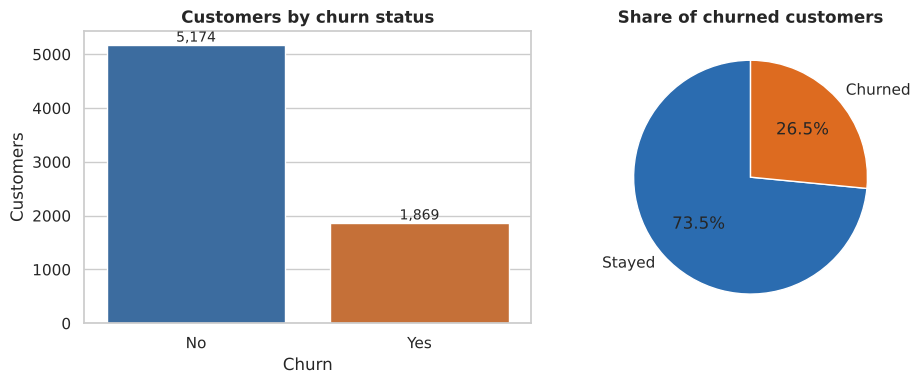

In [6]:
vc = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": vc, "percent": pct.round(2)}))
RESULTS["churn_counts"] = {k: int(v) for k, v in vc.items()}
RESULTS["churn_rate"] = float(pct["Yes"])
RESULTS["imbalance_ratio"] = float(vc["No"] / vc["Yes"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="Churn", palette=COL, order=["No", "Yes"], ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)
ax[0].set_title("Customers by churn status"); ax[0].set_ylabel("Customers")
ax[1].pie(vc[["No", "Yes"]], labels=["Stayed", "Churned"], autopct="%1.1f%%", startangle=90,
          colors=[COL["No"], COL["Yes"]], wedgeprops={"edgecolor": "white"})
ax[1].set_title("Share of churned customers")
plt.tight_layout(); save_show(fig, "fig01_target")

**Interpretation.** Of the 7,043 customers, **5,174 (73.5 %) stayed and 1,869 (26.5 %) churned** - an imbalance ratio of about 2.8 : 1. The data are *moderately imbalanced*: a useless model that always answers "stay" would be 73.5 % accurate. Therefore **accuracy alone is not a trustworthy metric here**; we will focus on Recall, Precision, F1 and ROC-AUC of the churn class and will use SMOTE / class weights.

### 4.2 Numerical features: distributions and outliers

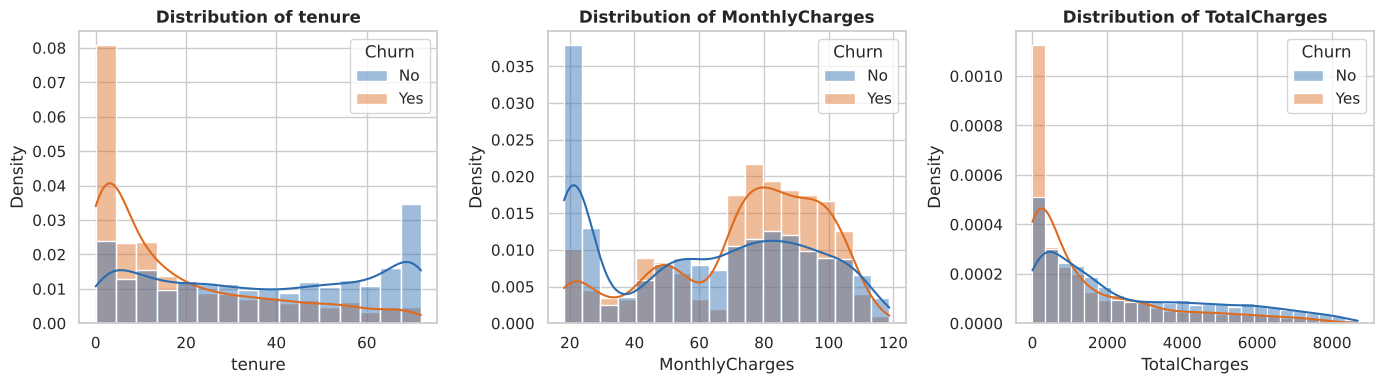

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

Skewness:
 tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, palette=COL, hue_order=["No", "Yes"],
                 stat="density", common_norm=False, alpha=.45, ax=a)
    a.set_title(f"Distribution of {c}")
plt.tight_layout(); save_show(fig, "fig02_numeric_dist")

summary = df.groupby("Churn")[num_cols].agg(["mean", "median"]).round(2)
display(summary)
RESULTS["num_by_churn"] = {c: {"mean_stay": float(df[df.Churn=="No"][c].mean()), "mean_churn": float(df[df.Churn=="Yes"][c].mean()),
                               "median_stay": float(df[df.Churn=="No"][c].median()), "median_churn": float(df[df.Churn=="Yes"][c].median())} for c in num_cols}
print("Skewness:\n", df[num_cols].skew().round(2))

**Interpretation of the histograms and summary table**
- **tenure:** churners are concentrated at the very beginning of the relationship (mean 18.0 months, median 10) whereas loyal customers have a mean of 37.6 months (median 38) and a large group at 70+ months. *Customers who survive the first year rarely leave.*
- **MonthlyCharges:** churners pay more (mean 74.4 vs 61.3). Many loyal customers sit in the cheap 20-30 band (basic phone-only plans), while churners cluster at 70-100 (fibre + add-ons).
- **TotalCharges:** it is right-skewed and mostly mirrors tenure (low tenure -> low total), so churners have lower totals (median 704 vs 1,680).

,feature,Q1,Q3,lower_fence,upper_fence,n_outliers,min,max
0,tenure,9.00,55.00,-60.00,124.00,0,0.00,72.00
1,MonthlyCharges,35.50,89.85,-46.02,171.38,0,18.25,118.75
2,TotalCharges,398.55,3786.60,-4683.52,8868.67,0,0.00,8684.80


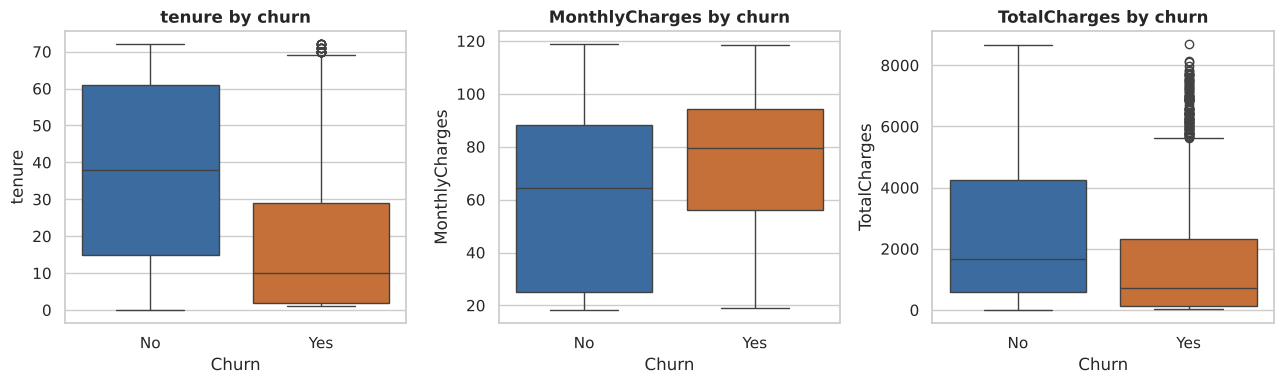

In [8]:
# ---- Outlier detection: IQR rule (value < Q1-1.5*IQR or > Q3+1.5*IQR) ----
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "Q1": q1, "Q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "n_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()), "min": df[c].min(), "max": df[c].max()})
out_tbl = pd.DataFrame(rows).round(2)
display(out_tbl)
RESULTS["outliers"] = out_tbl.set_index("feature")["n_outliers"].to_dict()

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, order=["No", "Yes"], palette=COL, ax=a)
    a.set_title(f"{c} by churn")
plt.tight_layout(); save_show(fig, "fig03_boxplots")

**Interpretation of the outlier check.** With the IQR rule applied to the whole data set, **no value of `tenure`, `MonthlyCharges` or `TotalCharges` lies outside the fences (0 outliers in each)**: the values are bounded business quantities (0-72 months, 18-119 monthly charge). The few dots visible on the *churn* boxes are only unusual relative to that group's own narrower spread (e.g. long-tenure or high-total churners) - they are genuine customers, not errors. Because removing real customers would delete exactly the interesting cases, **no outliers are removed or capped**. Standard scaling is applied later because the three features are on very different scales.

### 4.3 Categorical features vs churn

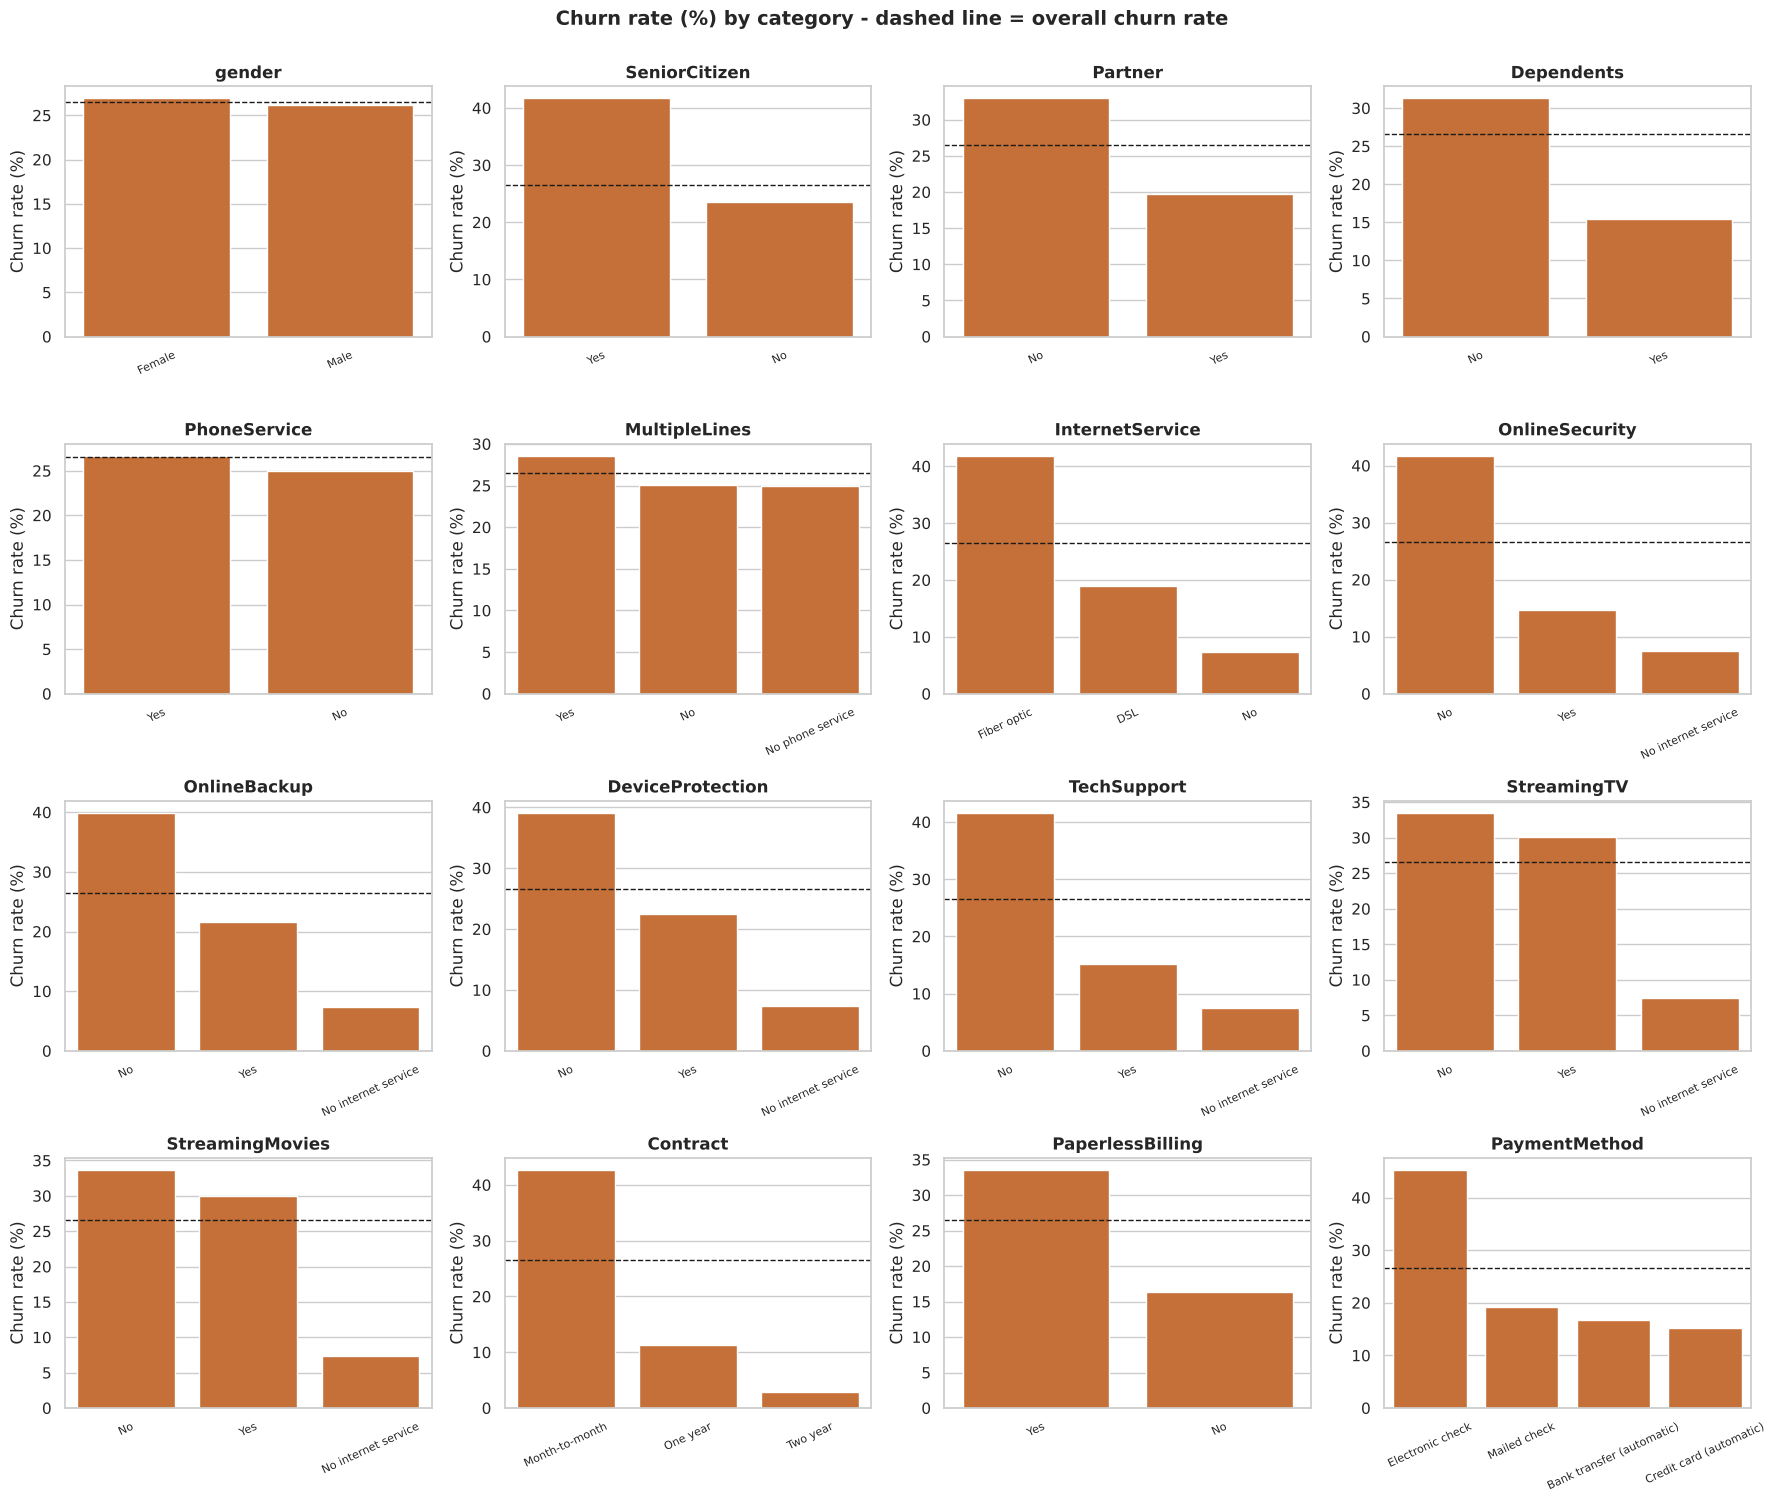

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
rate_tbl = {}
for a, c in zip(axes.ravel(), cat_cols):
    r = df.groupby(c)["Churn_flag"].mean().sort_values(ascending=False) * 100
    rate_tbl[c] = r.round(1).to_dict()
    sns.barplot(x=r.index.astype(str), y=r.values, color="#DD6B20", ax=a)
    a.axhline(df["Churn_flag"].mean() * 100, color="k", ls="--", lw=1)
    a.set_title(c); a.set_ylabel("Churn rate (%)"); a.set_xlabel("")
    a.tick_params(axis="x", rotation=25, labelsize=8)
for a in axes.ravel()[len(cat_cols):]: a.axis("off")
fig.suptitle("Churn rate (%) by category - dashed line = overall churn rate", y=1.0, fontsize=14, fontweight="bold")
plt.tight_layout(); save_show(fig, "fig04_cat_churn")
RESULTS["churn_rate_by_cat"] = rate_tbl

**Interpretation of the churn-rate bar charts (dashed line = overall 26.5 %)**
- **Contract** is the dominant factor: month-to-month **42.7 %**, one-year 11.3 %, two-year only 2.8 %.
- **Internet service:** fibre-optic customers churn at **41.9 %** versus 19.0 % for DSL and 7.4 % for customers without internet - fibre is more expensive and, in this data, linked to dissatisfaction.
- **Support add-ons protect:** customers *without* Online Security churn 41.8 % (vs 14.6 % with it); without Tech Support 41.6 % (vs 15.2 %). Similar pattern for Online Backup and Device Protection.
- **Payment method:** electronic-check users churn at **45.3 %**, far above automatic bank transfer (16.7 %) and credit card (15.2 %).
- **Demographics:** senior citizens churn more (41.7 % vs 23.6 %); customers without a partner (33.0 % vs 19.7 %) or dependents (31.3 % vs 15.5 %) churn more. Paperless billing: 33.6 % vs 16.3 %.
- **gender** (26.9 % vs 26.2 %) and **PhoneService** (26.7 % vs 24.9 %) show almost no difference.

In [10]:
# Chi-square test of independence between each categorical feature and churn
rows = []
for c in cat_cols:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[c], df["Churn"]))
    n = len(df); cramers_v = np.sqrt(chi2 / (n * (min(pd.crosstab(df[c], df["Churn"]).shape) - 1)))
    rows.append({"feature": c, "chi2": chi2, "p_value": p, "Cramers_V": cramers_v})
chi_tbl = pd.DataFrame(rows).sort_values("Cramers_V", ascending=False).round(4)
display(chi_tbl)
RESULTS["chi2_top"] = chi_tbl.head(6)[["feature", "Cramers_V"]].to_dict("records")
RESULTS["chi2_not_sig"] = chi_tbl[chi_tbl.p_value > 0.05]["feature"].tolist()

,feature,chi2,p_value,Cramers_V
13,Contract,1184.5966,0.0000,0.4101
7,OnlineSecurity,849.9990,0.0000,0.3474
10,TechSupport,828.1971,0.0000,0.3429
6,InternetService,732.3096,0.0000,0.3225
15,PaymentMethod,648.1423,0.0000,0.3034
8,OnlineBackup,601.8128,0.0000,0.2923
9,DeviceProtection,558.4194,0.0000,0.2816
12,StreamingMovies,375.6615,0.0000,0.2310
11,StreamingTV,374.2039,0.0000,0.2305
14,PaperlessBilling,258.2776,0.0000,0.1915


**Interpretation.** The chi-square test asks "are this feature and churn independent?"; **Cramér's V** (0 = no association, 1 = perfect) measures the strength. The strongest associations are `Contract` (V = 0.41), `OnlineSecurity` (0.35), `TechSupport` (0.34), `InternetService` (0.32), `PaymentMethod` (0.30) and `OnlineBackup` (0.29). Only **`gender` and `PhoneService`** have a p-value above 0.05, i.e. no statistically significant relation to churn - matching the bar charts. They are kept in the models (harmless) and the models themselves will confirm their low importance.

### 4.4 Correlation analysis

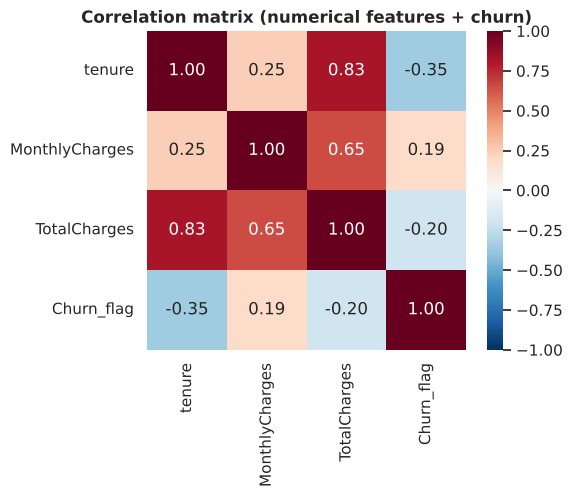

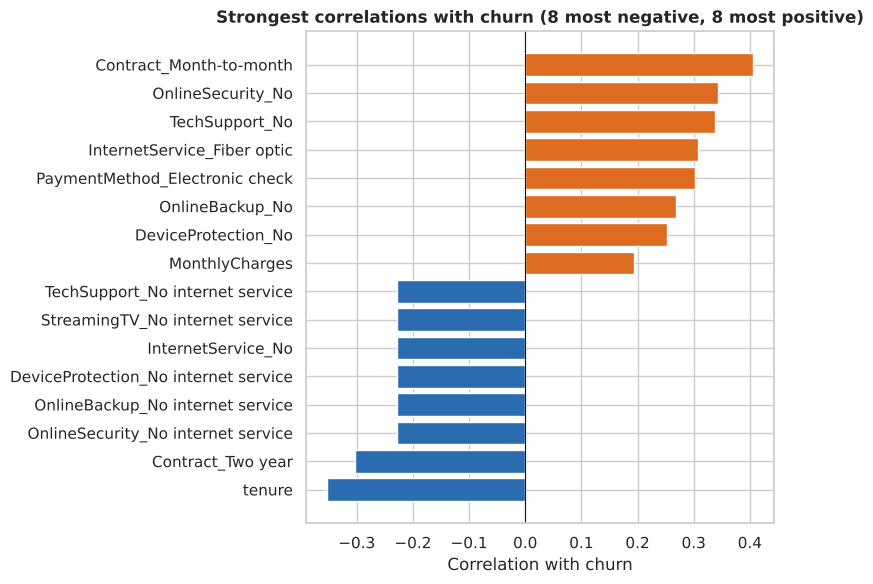

In [11]:
# Correlation among numeric features and the churn flag
corr = df[num_cols + ["Churn_flag"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix (numerical features + churn)")
plt.tight_layout(); save_show(fig, "fig05_corr_heatmap")
RESULTS["corr_num"] = corr.round(3).to_dict()

# Correlation of every one-hot encoded feature with churn (point-biserial = Pearson with 0/1 target)
enc = pd.get_dummies(df.drop(columns=["customerID", "Churn"]), columns=cat_cols, drop_first=False).astype(float)
cc = enc.corr()["Churn_flag"].drop("Churn_flag").sort_values()
top = pd.concat([cc.head(8), cc.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=["#2B6CB0" if v < 0 else "#DD6B20" for v in top.values])
ax.axvline(0, color="k", lw=.8); ax.set_title("Strongest correlations with churn (8 most negative, 8 most positive)")
ax.set_xlabel("Correlation with churn")
plt.tight_layout(); save_show(fig, "fig06_top_corr")
RESULTS["top_corr"] = {k: float(v) for k, v in top.items()}

**Interpretation of the correlation analysis**
- `tenure` has the strongest linear link with churn (**-0.35**): longer tenure -> less churn. `MonthlyCharges` is positively related (+0.19) and `TotalCharges` negatively (-0.20).
- `tenure` and `TotalCharges` are **highly correlated (0.83)** because total charges accumulate over time. This *multicollinearity* is harmless for tree models but makes individual coefficients of Logistic Regression unstable (seen later in the odds-ratio plot).
- Among encoded categories, **month-to-month contract (+0.41)**, no online security (+0.34), no tech support (+0.34), fibre-optic internet (+0.31) and electronic-check payment (+0.30) are the strongest risk indicators; two-year contract (-0.30) and having no internet service (-0.23) are the strongest protective ones. (The "No internet service" dummies are identical copies of each other, hence identical correlations.)

### 4.5 Tenure and contract - the strongest business story

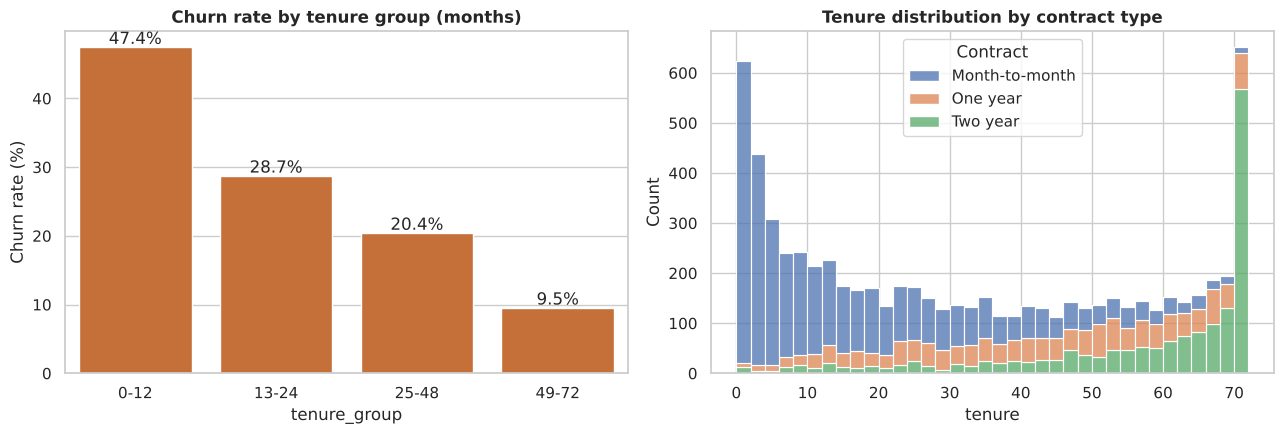

In [12]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
g = df.groupby("tenure_group", observed=True)["Churn_flag"].mean() * 100
sns.barplot(x=g.index.astype(str), y=g.values, color="#DD6B20", ax=ax[0])
for i, v in enumerate(g.values): ax[0].text(i, v + .5, f"{v:.1f}%", ha="center")
ax[0].set_title("Churn rate by tenure group (months)"); ax[0].set_ylabel("Churn rate (%)")

sns.histplot(data=df, x="tenure", hue="Contract", multiple="stack", bins=36, ax=ax[1])
ax[1].set_title("Tenure distribution by contract type")
plt.tight_layout(); save_show(fig, "fig07_tenure_contract")
RESULTS["churn_by_tenure_group"] = {str(k): float(v) for k, v in g.items()}
df.drop(columns="tenure_group", inplace=True)

**Interpretation.** Churn falls steadily with tenure: **47.4 %** in the first 12 months, 28.7 % (13-24 months), 20.4 % (25-48) and just **9.5 %** after four years. The right plot shows why long tenures are linked to contracts: customers with two-year contracts dominate the high-tenure end, whereas month-to-month customers are piled up in the first months. *The first year is the critical retention window.*

## 5. Data preprocessing and the 70/30 split
Decisions taken (with reasons):

| Step | Decision | Reason |
|---|---|---|
| Identifier | Drop `customerID` | Unique per row - it would only let the model memorise |
| Missing values | `TotalCharges` blanks -> 0 (tenure = 0); an imputer (median) stays in the pipeline as a safety net | The 11 blanks are brand-new customers who have not been billed yet |
| Outliers | **Kept** | IQR check found no genuine outliers in the numerical features (see 4.2); nothing to remove |
| Encoding | One-hot encoding of the categorical features (binary Yes/No columns become one 0/1 column) | Models need numbers; the categories have no natural order so ordinal codes would be misleading |
| Scaling | `StandardScaler` on numerical features | Needed by Logistic Regression and KNN (distance-based); harmless for trees |
| Split | **70 % train / 30 % test**, stratified, `random_state = 42` | Assignment requirement; stratification keeps the churn ratio equal in both parts |
| Leakage control | Encoder + scaler (and later SMOTE) are inside a **Pipeline**, so they are fitted on training data only (also inside every cross-validation fold) | Prevents test/validation information leaking into training |

In [13]:
X = df.drop(columns=["customerID", "Churn", "Churn_flag"])
y = df["Churn_flag"]

# 70 % training / 30 % testing, stratified so both sets keep the same churn proportion
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate  train: %.2f%%   test: %.2f%%" % (y_train.mean() * 100, y_test.mean() * 100))
RESULTS.update(n_train=int(len(X_train)), n_test=int(len(X_test)),
               churn_train=float(y_train.mean() * 100), churn_test=float(y_test.mean() * 100))

Train: (4930, 19)  Test: (2113, 19)
Churn rate  train: 26.53%   test: 26.55%


In [14]:
def make_preprocessor():
    """Numeric: median-impute -> standardise.  Categorical: one-hot (binary columns -> single 0/1 column)."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

# Demonstration: fit on TRAIN only, then transform train and test
pre_demo = make_preprocessor().fit(X_train)
Xtr_enc = pre_demo.transform(X_train); Xte_enc = pre_demo.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in pre_demo.get_feature_names_out()]
print("Encoded feature count:", len(feature_names), "| train matrix:", Xtr_enc.shape, "| test matrix:", Xte_enc.shape)
print("Scaled numeric columns on TRAIN -> mean ~ 0, std ~ 1:", Xtr_enc[:, :3].mean(0).round(3), Xtr_enc[:, :3].std(0).round(3))
print("Scaled numeric columns on TEST  -> not exactly 0/1 (uses train statistics):", Xte_enc[:, :3].mean(0).round(3), Xte_enc[:, :3].std(0).round(3))
RESULTS["n_encoded_features"] = len(feature_names)
pd.DataFrame(Xtr_enc[:5], columns=feature_names).round(2).iloc[:, :12]

Encoded feature count: 40 | train matrix: (4930, 40) | test matrix: (2113, 40)
Scaled numeric columns on TRAIN -> mean ~ 0, std ~ 1: [-0.  0. -0.] [1. 1. 1.]
Scaled numeric columns on TEST  -> not exactly 0/1 (uses train statistics): [-0.014 -0.021 -0.032] [0.988 0.983 0.962]


,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL
0,-1.11,0.50,-0.84,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,-1.20,0.72,-0.91,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2,-1.20,0.34,-0.91,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.12,0.52,1.11,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
4,-0.83,1.12,-0.52,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


**Interpretation.** After one-hot encoding the model sees **40 numerical input columns** (3 scaled numerical + 37 encoded categorical). On the *training* data the scaled numerical columns have mean ~0 and standard deviation 1; on the *test* data they are close to, but not exactly, 0 and 1 - which proves that the scaler learned its mean/std **from the training set only** and merely applied them to the test set (no data leakage). The split gives **4,930 training** and **2,113 test** customers with the same churn rate (26.5 %) in both.

In [15]:
def make_pipe(clf, smote=False):
    steps = [("pre", make_preprocessor())]
    if smote: steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return Pipeline(steps)

def evaluate(name, pipe, tag=""):
    """Metrics on the 30 % test set (positive class = churn) plus train F1/accuracy to check over-fitting."""
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    return {"Model": name, "Stage": tag,
            "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC_AUC": roc_auc_score(y_test, proba),
            "Train_Acc": accuracy_score(y_train, pipe.predict(X_train)), "Train_F1": f1_score(y_train, pipe.predict(X_train))}

def cm_plot(ax, pipe, title):
    ConfusionMatrixDisplay.from_predictions(y_test, pipe.predict(X_test), display_labels=["Stay", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title); ax.grid(False)

CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 6. Baseline machine learning models
All three baselines use (almost) default settings. Each is wrapped in a pipeline `preprocessing -> classifier`.

**Evaluation metrics** (churn = the *positive* class)
- **Accuracy** = correct predictions / all predictions. Can be misleading with imbalance (always predicting "stay" already gives about 73 %).
- **Precision** = of the customers we flag as churners, how many really churn. (Cost of wasted retention offers.)
- **Recall** = of all real churners, how many we catch. (Cost of lost customers.)
- **F1** = harmonic mean of precision and recall - one balanced number for the minority class.
- **Confusion matrix** = counts of TN, FP, FN, TP.
- **ROC-AUC** = probability that a random churner gets a higher score than a random loyal customer (0.5 = guessing, 1 = perfect).

**How the algorithms work**
- **Logistic Regression** - learns a weighted sum of the features and squashes it through a sigmoid to get a churn *probability*. Linear decision boundary, fast and easy to interpret (coefficients become odds ratios).
- **Decision Tree** - repeatedly asks yes/no questions (e.g. "Contract = month-to-month?") that best split churners from non-churners. Easy to visualise, but an unrestricted tree keeps splitting until it memorises the training data (over-fitting).
- **K-Nearest Neighbours (KNN)** - predicts the majority class of the *k* most similar customers (distance in scaled feature space). No training phase, but sensitive to scaling, to *k* and to many one-hot columns.

,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Acc,Train_F1
Model,,,,,,,
Logistic Regression,0.8093,0.6674,0.5615,0.6099,0.8449,0.8041,0.5985
Decision Tree,0.7331,0.4973,0.4920,0.4946,0.6563,0.9980,0.9962
KNN,0.7643,0.5576,0.5437,0.5505,0.7846,0.8387,0.6806


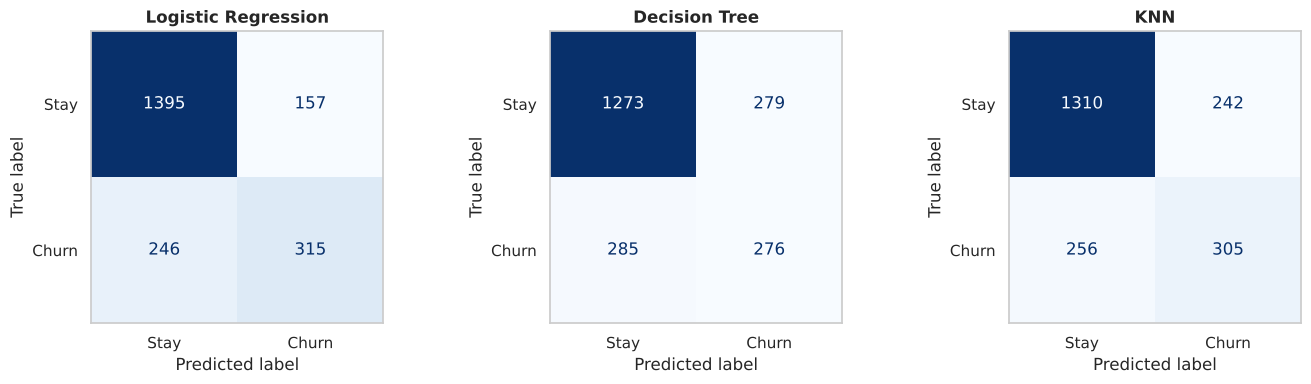

 Logistic Regression
              precision    recall  f1-score   support

        Stay      0.850     0.899     0.874      1552
       Churn      0.667     0.561     0.610       561

    accuracy                          0.809      2113
   macro avg      0.759     0.730     0.742      2113
weighted avg      0.802     0.809     0.804      2113

 Decision Tree
              precision    recall  f1-score   support

        Stay      0.817     0.820     0.819      1552
       Churn      0.497     0.492     0.495       561

    accuracy                          0.733      2113
   macro avg      0.657     0.656     0.657      2113
weighted avg      0.732     0.733     0.733      2113

 KNN
              precision    recall  f1-score   support

        Stay      0.837     0.844     0.840      1552
       Churn      0.558     0.544     0.551       561

    accuracy                          0.764      2113
   macro avg      0.697     0.694     0.695      2113
weighted avg      0.762     0.764

In [16]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=5),
}
fitted_base, rows = {}, []
for name, clf in baseline_models.items():
    p = make_pipe(clf).fit(X_train, y_train)
    fitted_base[name] = p
    rows.append(evaluate(name, p, "Baseline"))

base_tbl = pd.DataFrame(rows).set_index("Model").drop(columns="Stage")
display(base_tbl.round(4))
RESULTS["baseline"] = base_tbl.to_dict("index")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (n, p) in zip(ax, fitted_base.items()): cm_plot(a, p, n)
plt.tight_layout(); save_show(fig, "fig08_baseline_cm")

for n, p in fitted_base.items():
    print("=" * 60, "\n", n); print(classification_report(y_test, p.predict(X_test), target_names=["Stay", "Churn"], digits=3))
RESULTS["baseline_cm"] = {n: confusion_matrix(y_test, p.predict(X_test)).tolist() for n, p in fitted_base.items()}

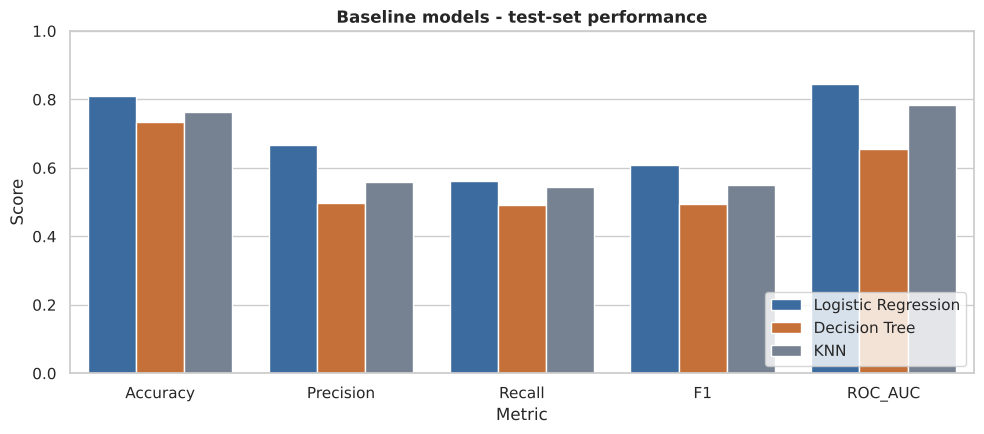

In [17]:
m = base_tbl[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=m, x="Metric", y="Score", hue="Model", palette=["#2B6CB0", "#DD6B20", "#718096"], ax=ax)
ax.set_ylim(0, 1); ax.set_title("Baseline models - test-set performance"); ax.legend(loc="lower right")
plt.tight_layout(); save_show(fig, "fig09_baseline_compare")

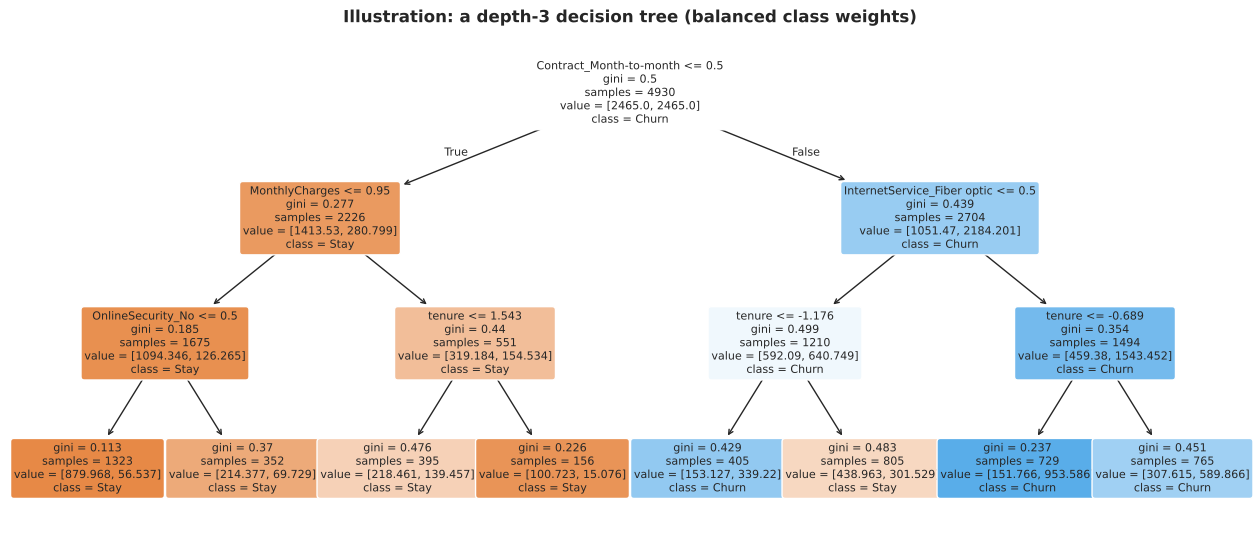

In [18]:
# Small depth-3 tree, only to SEE what a decision tree learns (not used for evaluation)
viz_pre = make_preprocessor().fit(X_train)
viz_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE, class_weight="balanced").fit(viz_pre.transform(X_train), y_train)
fig, ax = plt.subplots(figsize=(16, 6.5))
plot_tree(viz_tree, feature_names=feature_names, class_names=["Stay", "Churn"], filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Illustration: a depth-3 decision tree (balanced class weights)")
save_show(fig, "fig10_tree_illustration")

**Interpretation of the baseline results** (test set: 2,113 customers, of which 561 are churners; always predicting "stay" would give 73.4 % accuracy)

| Model | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.809 | 0.667 | 0.562 | **0.610** | **0.845** |
| Decision Tree | 0.733 | 0.497 | 0.492 | 0.495 | 0.656 |
| KNN (k=5) | 0.764 | 0.558 | 0.544 | 0.551 | 0.785 |

- **Logistic Regression is the best baseline** on every metric. It beats the 73.4 % "always stay" benchmark clearly and is very stable (train accuracy 0.804 vs test 0.809).
- **The default Decision Tree over-fits badly**: training accuracy 0.998 but test accuracy only 0.733 - it memorised the training customers. Its AUC of 0.656 is poor.
- **KNN** is in between; with k = 5 it is sensitive to noise and to the 40-dimensional one-hot space.
- All three baselines **miss many churners**: recall is only 49-56 %. For LR the confusion matrix shows 315 churners caught and 246 missed (FN) while 157 loyal customers were wrongly flagged (FP). For a retention team, missed churners are costly, so we need to improve recall (Section 8).
- The depth-3 tree illustration confirms what EDA suggested: the very first split is **month-to-month contract or not**; the next questions are about fibre-optic internet, monthly charges, tenure and online security. (Numerical thresholds in the plot are in *standardised* units, e.g. tenure <= -1.18 means roughly the first year.)

## 7. Advanced machine learning models
- **Random Forest** - builds many decision trees, each on a random bootstrap sample and a random subset of features, and averages their votes. Averaging removes much of the single tree's over-fitting (variance reduction).
- **Gradient Boosting** - builds shallow trees *one after another*, each new tree correcting the errors of the previous ones (bias reduction). Usually very accurate but needs careful tuning of learning rate and number of trees. (scikit-learn's `GradientBoostingClassifier` is used; XGBoost is an alternative implementation of the same idea.)

First we train them with **default** settings so that tuning gains can be measured fairly.

In [19]:
adv_models = {
    "Random Forest":     RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
for name, clf in adv_models.items():
    p = make_pipe(clf).fit(X_train, y_train)
    fitted_base[name] = p
    rows.append(evaluate(name, p, "Default"))

default_tbl = pd.DataFrame(rows).drop_duplicates("Model", keep="last").set_index("Model").drop(columns="Stage")
display(default_tbl.round(4))
RESULTS["default_all"] = default_tbl.to_dict("index")

,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Acc,Train_F1
Model,,,,,,,
Logistic Regression,0.8093,0.6674,0.5615,0.6099,0.8449,0.8041,0.5985
Decision Tree,0.7331,0.4973,0.4920,0.4946,0.6563,0.9980,0.9962
KNN,0.7643,0.5576,0.5437,0.5505,0.7846,0.8387,0.6806
Random Forest,0.7809,0.6089,0.4884,0.5420,0.8166,0.9980,0.9962
Gradient Boosting,0.7965,0.6541,0.4955,0.5639,0.8402,0.8337,0.6528


**Interpretation.** With default settings Random Forest (F1 0.542, AUC 0.817) and Gradient Boosting (F1 0.564, AUC 0.840) do **not** yet beat Logistic Regression (F1 0.610, AUC 0.845). The default Random Forest has a training accuracy of 0.998 vs 0.781 on test - it still over-fits (fully grown trees). Default Gradient Boosting generalises better (train 0.834 / test 0.797) and has the highest AUC of the two. All default models still have recall below 0.56, i.e. the class imbalance hurts them. Advanced models need **imbalance handling and tuning** to show their strength.

## 8. Handling class imbalance
Only about a quarter of customers churn, so a model can score high accuracy by favouring the majority class while missing churners (low recall). Two standard remedies:
- **Class weights** (`class_weight="balanced"`): mistakes on the minority class cost more during training.
- **SMOTE** (Synthetic Minority Over-sampling Technique): creates *synthetic* churners by interpolating between existing churners and their nearest neighbours. It is applied **only to training folds** (inside the pipeline) - never to validation/test data.

We compare "None / SMOTE / class_weight" using 5-fold CV on the **training** set only.

Training churn counts: {0: 3622, 1: 1308}


,Model,Strategy,CV_F1,CV_Recall,CV_Precision,CV_AUC
0,Logistic Regression,None,0.5952,0.5474,0.6536,0.8444
1,Logistic Regression,SMOTE,0.6284,0.7951,0.5198,0.8437
2,Logistic Regression,class_weight=balanced,0.6250,0.8035,0.5118,0.8442
3,Decision Tree,None,0.5623,0.5214,0.6173,0.8223
4,Decision Tree,SMOTE,0.6066,0.7049,0.5342,0.8100
5,Decision Tree,class_weight=balanced,0.6174,0.7698,0.5173,0.8237
6,KNN,None,0.5863,0.5642,0.6107,0.8208
7,KNN,SMOTE,0.5821,0.8104,0.4544,0.8079
8,Random Forest,None,0.5799,0.5115,0.6700,0.8463
9,Random Forest,SMOTE,0.6278,0.7247,0.5541,0.8416


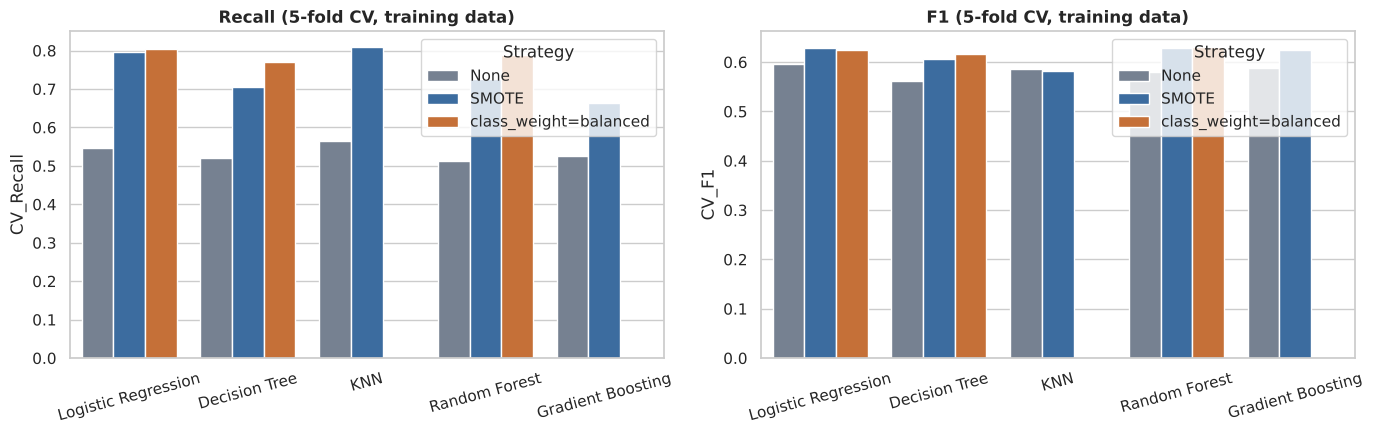

In [20]:
# Compare 3 ways to deal with the 73:27 imbalance using 5-fold CV on the TRAINING set only
# (SMOTE sits inside the pipeline, so it is applied to the training part of each fold only -> no leakage)
print("Training churn counts:", y_train.value_counts().to_dict())
strategy_models = {
    "Logistic Regression": lambda cw: LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE),
    "Decision Tree":       lambda cw: DecisionTreeClassifier(max_depth=5, class_weight=cw, random_state=RANDOM_STATE),
    "KNN":                 lambda cw: KNeighborsClassifier(n_neighbors=15),
    "Random Forest":       lambda cw: RandomForestClassifier(n_estimators=200, max_depth=8, class_weight=cw, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   lambda cw: GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows_imb = []
for name, mk in strategy_models.items():
    strategies = {"None": make_pipe(mk(None)), "SMOTE": make_pipe(mk(None), smote=True)}
    if name not in ("KNN", "Gradient Boosting"):          # these estimators have no class_weight option
        strategies["class_weight=balanced"] = make_pipe(mk("balanced"))
    for s, pipe in strategies.items():
        cv = cross_validate(pipe, X_train, y_train, cv=CV5, scoring=["f1", "recall", "precision", "roc_auc"], n_jobs=-1)
        rows_imb.append({"Model": name, "Strategy": s, "CV_F1": cv["test_f1"].mean(), "CV_Recall": cv["test_recall"].mean(),
                         "CV_Precision": cv["test_precision"].mean(), "CV_AUC": cv["test_roc_auc"].mean()})
imb_tbl = pd.DataFrame(rows_imb)
display(imb_tbl.round(4))
RESULTS["imbalance_cv"] = imb_tbl.to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for a, met in zip(ax, ["CV_Recall", "CV_F1"]):
    sns.barplot(data=imb_tbl, x="Model", y=met, hue="Strategy", palette=["#718096", "#2B6CB0", "#DD6B20"], ax=a)
    a.set_title(f"{met.replace('CV_', '')} (5-fold CV, training data)"); a.tick_params(axis="x", rotation=15); a.set_xlabel("")
plt.tight_layout(); save_show(fig, "fig11_imbalance")

**Interpretation (5-fold CV on the training set)**
- Without any handling, recall of the churn class is only **0.51-0.56** for all models: the models are biased towards the majority class.
- **SMOTE and class weights both raise recall strongly** (e.g. Logistic Regression 0.547 -> 0.795 (SMOTE) / 0.804 (class weight); Decision Tree 0.521 -> 0.705 / 0.770; Random Forest 0.511 -> 0.725 / 0.787; KNN 0.564 -> 0.810; Gradient Boosting 0.527 -> 0.663 with SMOTE).
- **F1 improves** for four of the five models (LR 0.595 -> 0.628, DT 0.562 -> 0.617, RF 0.580 -> 0.631, GB 0.589 -> 0.625). **KNN is the exception:** SMOTE raises recall but lowers precision so much that F1 does not improve (0.586 -> 0.582).
- Class weights and SMOTE give similar results; class weights are simpler and faster, SMOTE is the only option for models without a `class_weight` parameter (KNN, Gradient Boosting). The trade-off is that *precision falls* (more false alarms) - acceptable when a missed churner costs more than an unnecessary retention offer.
- These findings are fed into GridSearchCV, which can pick SMOTE, class weights or neither for each model.

## 9. Hyper-parameter tuning (GridSearchCV)
`GridSearchCV` tries every combination in a parameter grid, scores each with 5-fold stratified cross-validation and keeps the best. Scoring metric: **F1 of the churn class**, because we care about the minority class and want a balance between precision and recall. The grid also contains the imbalance strategy (SMOTE on/off, class weights), so the data decides the best strategy per model.

In [21]:
# ---- Hyperparameter tuning with GridSearchCV (5-fold stratified CV, scoring = F1 of the churn class) ----
# SMOTE (on/off) and class_weight are part of the grid, so the data decides which imbalance strategy is best.
SM = [SMOTE(random_state=RANDOM_STATE), "passthrough"]
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"], "smote": SM}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [3, 5, 7, 10, None], "clf__min_samples_leaf": [1, 10, 30], "clf__class_weight": [None, "balanced"], "smote": SM}),
    "KNN": (KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31, 41, 51], "clf__weights": ["uniform", "distance"], "smote": SM}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"clf__n_estimators": [300], "clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [1, 5],
         "clf__class_weight": [None, "balanced"], "smote": SM}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3], "smote": SM}),
}

tuned, tuned_rows, grid_info = {}, [], {}
for name, (clf, pg) in grids.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf, smote=True), pg, scoring="f1", cv=CV5, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    bp = {k.replace("clf__", ""): ("SMOTE" if (k == "smote" and v != "passthrough") else ("none" if k == "smote" else v)) for k, v in gs.best_params_.items()}
    n_fits = len(gs.cv_results_["params"]) * 5
    grid_info[name] = {"best_params": {k: (str(v) if v is None else v) for k, v in bp.items()}, "best_cv_f1": float(gs.best_score_),
                       "n_combinations": len(gs.cv_results_["params"])}
    r = evaluate(name, gs.best_estimator_, "Tuned"); r["Best_CV_F1"] = gs.best_score_
    tuned_rows.append(r)
    print(f"{name:20s} | {len(gs.cv_results_['params']):3d} combos ({n_fits} fits) | {time.time()-t0:5.1f}s | best CV F1 = {gs.best_score_:.4f}\n   best params: {bp}")
RESULTS["grid_info"] = grid_info

Logistic Regression  |  16 combos (80 fits) |   2.6s | best CV F1 = 0.6305
   best params: {'C': 0.1, 'class_weight': None, 'smote': 'SMOTE'}


Decision Tree        |  60 combos (300 fits) |   8.6s | best CV F1 = 0.6174
   best params: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 1, 'smote': 'none'}


KNN                  |  24 combos (120 fits) |   4.4s | best CV F1 = 0.6020
   best params: {'n_neighbors': 31, 'weights': 'uniform', 'smote': 'none'}


Random Forest        |  24 combos (120 fits) |  67.5s | best CV F1 = 0.6316
   best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300, 'smote': 'none'}


Gradient Boosting    |  16 combos (80 fits) |  41.0s | best CV F1 = 0.6297
   best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'smote': 'SMOTE'}


,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Acc,Train_F1,Best_CV_F1
Model,,,,,,,,
Logistic Regression,0.7511,0.5205,0.7914,0.6280,0.8434,0.7523,0.6312,0.6305
Decision Tree,0.7108,0.4735,0.7968,0.5940,0.8281,0.7341,0.6289,0.6174
KNN,0.7894,0.6070,0.5865,0.5966,0.8313,0.8103,0.6282,0.6020
Random Forest,0.7563,0.5273,0.7914,0.6329,0.8415,0.8176,0.7216,0.6316
Gradient Boosting,0.7757,0.5595,0.7291,0.6331,0.8397,0.7907,0.6509,0.6297


,F1 before,F1 after,Recall before,Recall after,AUC before,AUC after,Accuracy before,Accuracy after
Model,,,,,,,,
Logistic Regression,0.6099,0.6280,0.5615,0.7914,0.8449,0.8434,0.8093,0.7511
Decision Tree,0.4946,0.5940,0.4920,0.7968,0.6563,0.8281,0.7331,0.7108
KNN,0.5505,0.5966,0.5437,0.5865,0.7846,0.8313,0.7643,0.7894
Random Forest,0.5420,0.6329,0.4884,0.7914,0.8166,0.8415,0.7809,0.7563
Gradient Boosting,0.5639,0.6331,0.4955,0.7291,0.8402,0.8397,0.7965,0.7757


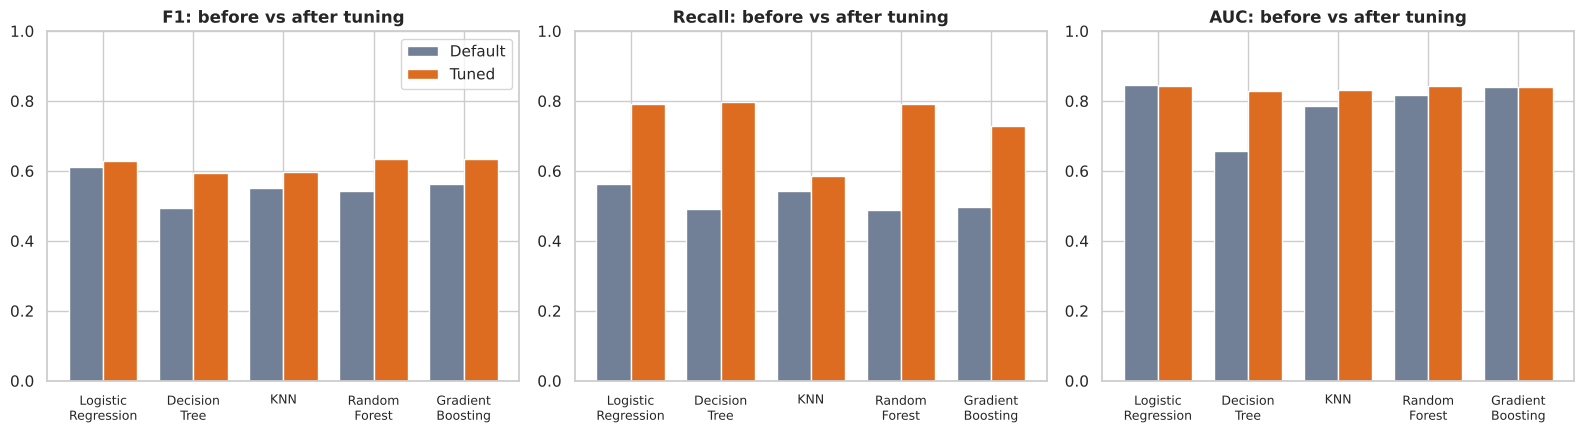

In [22]:
tuned_tbl = pd.DataFrame(tuned_rows).set_index("Model").drop(columns="Stage")
display(tuned_tbl.round(4))
RESULTS["tuned"] = tuned_tbl.to_dict("index")

# ---- Before vs after tuning (test set) ----
cmp_rows = []
for n in tuned_tbl.index:
    d = default_tbl.loc[n]; t = tuned_tbl.loc[n]
    cmp_rows.append({"Model": n, "F1 before": d["F1"], "F1 after": t["F1"], "Recall before": d["Recall"], "Recall after": t["Recall"],
                     "AUC before": d["ROC_AUC"], "AUC after": t["ROC_AUC"], "Accuracy before": d["Accuracy"], "Accuracy after": t["Accuracy"]})
cmp_tbl = pd.DataFrame(cmp_rows).set_index("Model")
display(cmp_tbl.round(4))
RESULTS["before_after"] = cmp_tbl.to_dict("index")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, met in zip(ax, ["F1", "Recall", "AUC"]):
    x = np.arange(len(cmp_tbl)); w = .38
    a.bar(x - w/2, cmp_tbl[f"{met} before"], w, label="Default", color="#718096")
    a.bar(x + w/2, cmp_tbl[f"{met} after"], w, label="Tuned", color="#DD6B20")
    a.set_xticks(x); a.set_xticklabels([n.replace(" ", "\n") for n in cmp_tbl.index], fontsize=9)
    a.set_title(f"{met}: before vs after tuning"); a.set_ylim(0, 1)
ax[0].legend(); plt.tight_layout(); save_show(fig, "fig12_before_after")

**Interpretation of tuning**

| Model | Best settings found | Best CV F1 |
|---|---|---|
| Logistic Regression | C = 0.1, SMOTE | 0.6305 |
| Decision Tree | max_depth = 5, class_weight = balanced | 0.6174 |
| KNN | k = 31, uniform weights | 0.6020 |
| Random Forest | 300 trees, max_depth = 10, min_samples_leaf = 5, class_weight = balanced | 0.6316 |
| Gradient Boosting | learning_rate = 0.05, max_depth = 3, 100 trees, SMOTE | 0.6297 |

- **Every model improved in test F1** (LR 0.610 -> 0.628, DT 0.495 -> 0.594, KNN 0.551 -> 0.597, RF 0.542 -> 0.633, GB 0.564 -> 0.633). The biggest gains are for the models that over-fitted: the Decision Tree's AUC jumped from 0.656 to 0.828 and Random Forest's recall from 0.488 to 0.791.
- Tuning used **regularisation** (shallow trees, larger leaves, small learning rate, large k) - exactly the cure for over-fitting.
- **Accuracy goes down** for LR (0.809 -> 0.751), DT, RF and GB because the models now flag more customers as churners to catch more of them (recall rises, e.g. LR 0.56 -> 0.79). This is a *deliberate trade-off*, not a loss of quality: accuracy is dominated by the majority class, while F1 and recall describe the class we care about.
- Test F1 of LR, RF and GB are all within 0.005 of each other (0.628 - 0.633): after tuning, the three best models are practically tied. The simple models (DT, KNN) are about 0.03-0.04 behind.

## 10. Cross-validation
The grid-search score is slightly optimistic because the best combination was *chosen* using those same folds. As a check, each tuned pipeline is cross-validated again on a **fresh 5-fold split** (different random seed) of the training data. The mean and standard deviation show the performance and its stability; the training score shows over-fitting.

,accuracy (mean),accuracy (std),precision (mean),precision (std),recall (mean),recall (std),f1 (mean),f1 (std),roc_auc (mean),roc_auc (std),train_f1 (mean)
Model,,,,,,,,,,,
Logistic Regression,0.7521,0.0133,0.5221,0.0168,0.7828,0.0241,0.6263,0.0186,0.8409,0.0102,0.6345
Decision Tree,0.7199,0.0133,0.4830,0.0149,0.7752,0.0412,0.5947,0.0181,0.8215,0.0063,0.6401
KNN,0.7929,0.0058,0.6194,0.0156,0.5719,0.0243,0.5942,0.0122,0.8305,0.0073,0.6216
Random Forest,0.7586,0.0153,0.5311,0.0201,0.7767,0.0249,0.6308,0.0208,0.8466,0.0102,0.7254
Gradient Boosting,0.7809,0.0109,0.5699,0.0180,0.7140,0.0233,0.6336,0.0161,0.8427,0.0104,0.6555


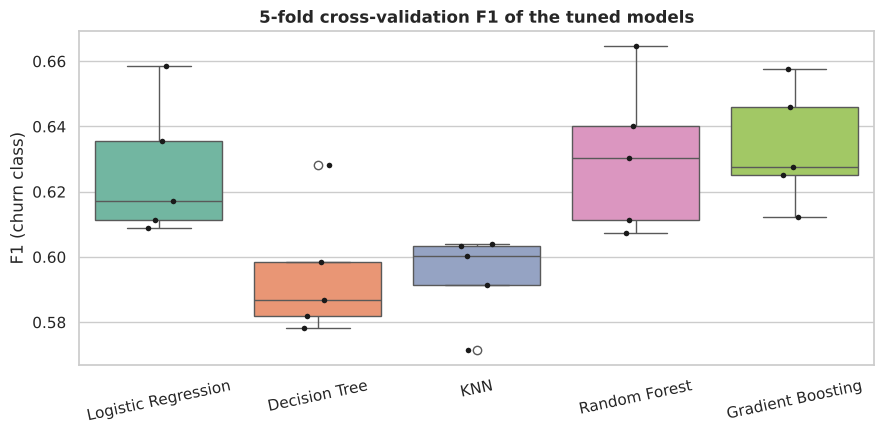

In [23]:
# ---- Cross-validation of the tuned models (fresh 5-fold split, training data only; train scores kept to study over-fitting) ----
CV_FRESH = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows, cv_f1 = [], {}
for name, gs in tuned.items():
    cv = cross_validate(gs.best_estimator_, X_train, y_train, cv=CV_FRESH, scoring=scoring, return_train_score=True, n_jobs=-1)
    cv_f1[name] = cv["test_f1"]
    row = {"Model": name}
    for m in scoring: row[f"{m} (mean)"] = cv[f"test_{m}"].mean(); row[f"{m} (std)"] = cv[f"test_{m}"].std()
    row["train_f1 (mean)"] = cv["train_f1"].mean()
    cv_rows.append(row)
cv_tbl = pd.DataFrame(cv_rows).set_index("Model")
display(cv_tbl.round(4))
RESULTS["cv_tuned"] = cv_tbl.to_dict("index")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=pd.DataFrame(cv_f1), palette="Set2", ax=ax); sns.stripplot(data=pd.DataFrame(cv_f1), color="k", size=4, ax=ax)
ax.set_ylabel("F1 (churn class)"); ax.set_title("5-fold cross-validation F1 of the tuned models"); ax.tick_params(axis="x", rotation=12)
plt.tight_layout(); save_show(fig, "fig13_cv_box")

**Interpretation of the cross-validation results.** Mean F1 over 5 folds: **Gradient Boosting 0.634**, Random Forest 0.631, Logistic Regression 0.626, KNN 0.594, Decision Tree 0.595; the fold-to-fold standard deviation is small (0.012-0.021), so the results are stable. The CV scores agree with the test scores (e.g. GB 0.634 CV vs 0.633 test), which shows the tuned models **generalise well and are not over-fitted to the test set**. Note that the differences between GB, RF and LR (about 0.003-0.008) are *smaller than one standard deviation*, so statistically the three are tied on F1; the boxplot shows heavily overlapping boxes.

## 11. Model comparison, ROC/AUC and final model selection
### 11.1 ROC and Precision-Recall curves

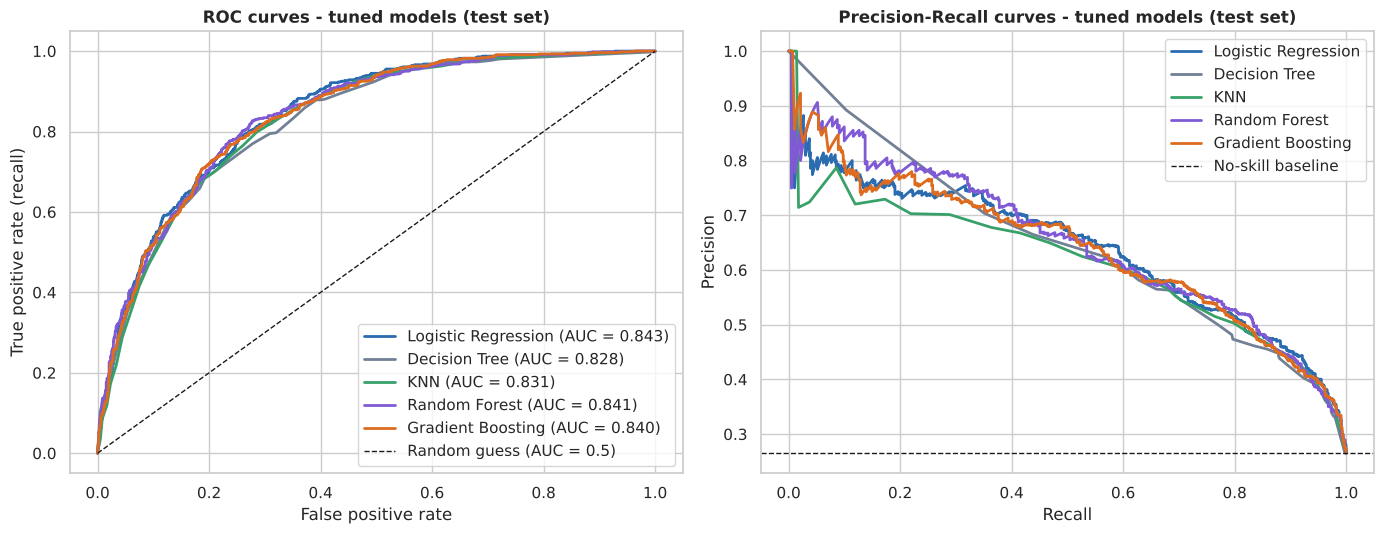

In [24]:
palette = {"Logistic Regression": "#2B6CB0", "Decision Tree": "#718096", "KNN": "#38A169", "Random Forest": "#805AD5", "Gradient Boosting": "#DD6B20"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for n, gs in tuned.items():
    pr = gs.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pr); ax[0].plot(fpr, tpr, lw=2, color=palette[n], label=f"{n} (AUC = {roc_auc_score(y_test, pr):.3f})")
    p_, r_, _ = precision_recall_curve(y_test, pr); ax[1].plot(r_, p_, lw=2, color=palette[n], label=n)
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.5)")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curves - tuned models (test set)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="No-skill baseline")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves - tuned models (test set)"); ax[1].legend(loc="upper right")
plt.tight_layout(); save_show(fig, "fig14_roc_pr")

**Interpretation.** All five curves lie far above the diagonal (random guessing, AUC 0.5). AUC on the test set: **Logistic Regression 0.843, Random Forest 0.841, Gradient Boosting 0.840, KNN 0.831, Decision Tree 0.828** - an AUC of ~0.84 means a randomly chosen churner receives a higher churn score than a randomly chosen loyal customer about 84 % of the time. The three best curves almost overlap, so ranking ability is almost identical. The precision-recall curves tell the same story: precision stays near 0.7 up to a recall of about 0.4, then drops as we try to catch more churners; the no-skill line is at 0.27 (the churn rate).

### 11.2 Selecting the final model
The final model is chosen **by cross-validated F1 on the training data**, not by looking at the test set, so the test score remains an honest, unbiased estimate.

In [25]:
# ---- Final model selection: highest CROSS-VALIDATED F1 on the training data (the test set is NOT used to choose) ----
sel = pd.DataFrame({"CV_F1_gridsearch": {n: g.best_score_ for n, g in tuned.items()},
                    "CV_F1_fresh_split": {n: v.mean() for n, v in cv_f1.items()},
                    "Test_F1": tuned_tbl["F1"], "Test_AUC": tuned_tbl["ROC_AUC"], "Test_Recall": tuned_tbl["Recall"]})
sel["Rank_by_CV"] = sel["CV_F1_fresh_split"].rank(ascending=False).astype(int)
display(sel.sort_values("Rank_by_CV").round(4))
final_name = sel["CV_F1_fresh_split"].idxmax()
final_pipe = tuned[final_name].best_estimator_
print("\nFINAL MODEL:", final_name, "\nBest parameters:", grid_info[final_name]["best_params"])
RESULTS["final_model"] = final_name
RESULTS["selection"] = sel.to_dict("index")
RESULTS["final_metrics"] = tuned_tbl.loc[final_name].to_dict()

,CV_F1_gridsearch,CV_F1_fresh_split,Test_F1,Test_AUC,Test_Recall,Rank_by_CV
Gradient Boosting,0.6297,0.6336,0.6331,0.8397,0.7291,1
Random Forest,0.6316,0.6308,0.6329,0.8415,0.7914,2
Logistic Regression,0.6305,0.6263,0.6280,0.8434,0.7914,3
Decision Tree,0.6174,0.5947,0.5940,0.8281,0.7968,4
KNN,0.6020,0.5942,0.5966,0.8313,0.5865,5



FINAL MODEL: Gradient Boosting 
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'smote': 'SMOTE'}


              precision    recall  f1-score   support

        Stay      0.890     0.793     0.838      1552
       Churn      0.560     0.729     0.633       561

    accuracy                          0.776      2113
   macro avg      0.725     0.761     0.736      2113
weighted avg      0.802     0.776     0.784      2113

TN=1230  FP=322  FN=152  TP=409


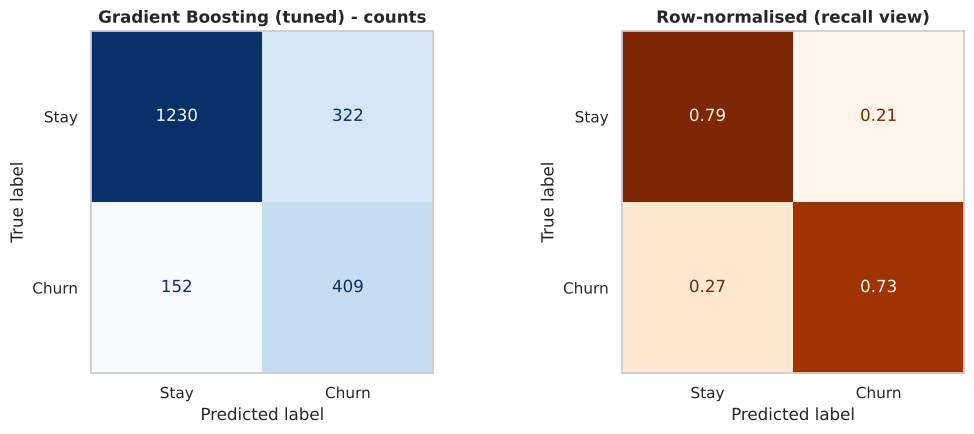

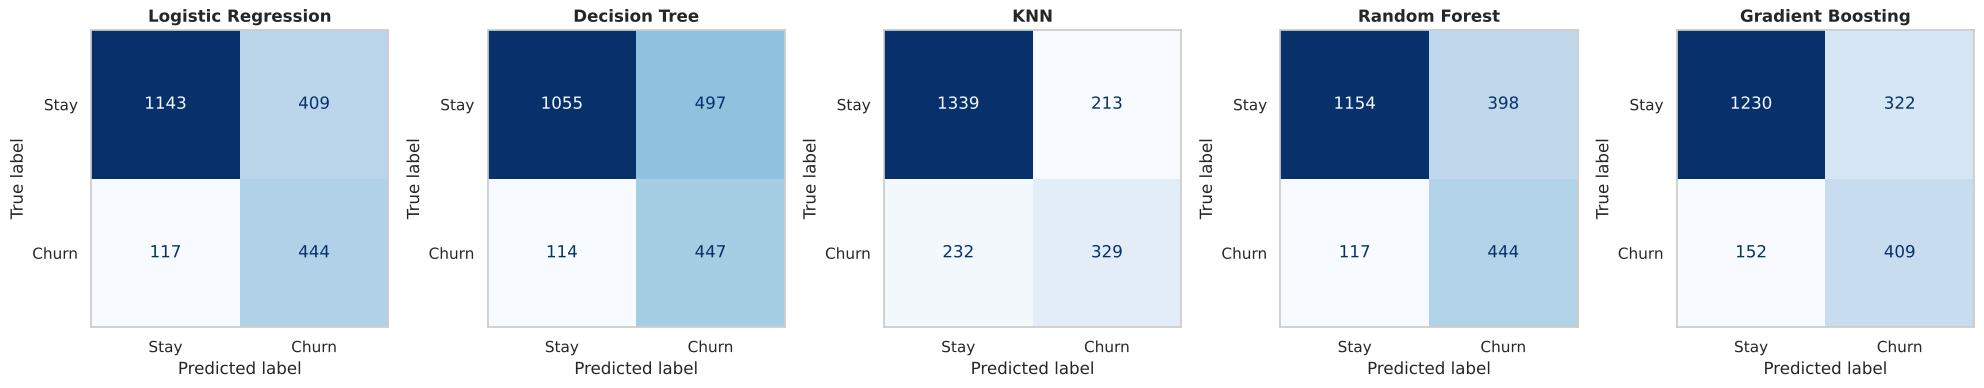

In [26]:
pred_f = final_pipe.predict(X_test); proba_f = final_pipe.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred_f, target_names=["Stay", "Churn"], digits=3))
cm = confusion_matrix(y_test, pred_f); tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
RESULTS["final_cm"] = {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
cm_plot(ax[0], final_pipe, f"{final_name} (tuned) - counts")
ConfusionMatrixDisplay.from_predictions(y_test, pred_f, display_labels=["Stay", "Churn"], normalize="true", cmap="Oranges",
                                        colorbar=False, values_format=".2f", ax=ax[1]); ax[1].set_title("Row-normalised (recall view)"); ax[1].grid(False)
plt.tight_layout(); save_show(fig, "fig15_final_cm")

# All tuned models' confusion matrices side by side
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
for a, (n, gs) in zip(ax, tuned.items()): cm_plot(a, gs.best_estimator_, n)
plt.tight_layout(); save_show(fig, "fig16_all_tuned_cm")
RESULTS["tuned_cm"] = {n: confusion_matrix(y_test, gs.best_estimator_.predict(X_test)).tolist() for n, gs in tuned.items()}

### Final model: **Gradient Boosting** (learning rate 0.05, max depth 3, 100 trees, SMOTE)

**Why this model?** The selection rule was fixed in advance: *highest cross-validated F1 on the training data*. Gradient Boosting won with 0.6336 (RF 0.6308, LR 0.6263). Its test results are:

| Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| 0.776 | 0.560 | 0.729 | 0.633 | 0.840 |

**Confusion matrix (2,113 test customers):** TN = 1,230 loyal customers correctly left alone; **TP = 409 churners caught**; FP = 322 loyal customers flagged unnecessarily; **FN = 152 churners missed**. It catches 73 % of churners, and 56 % of the customers it flags really would have left (vs 27 % if customers were picked at random - a lift of about 2.1x).

**Why it works well:** boosting builds small trees one after another, each correcting the mistakes of the previous ones, so it captures *interactions* (e.g. fibre internet **and** month-to-month contract **and** short tenure) that a single linear model cannot, and the small learning rate / shallow depth keep it from over-fitting. **Honest note:** its advantage over the much simpler tuned Logistic Regression is tiny (F1 0.633 vs 0.628; LR even has the highest test AUC, 0.843), so LR is a legitimate, easier-to-explain alternative when interpretability matters most.

In [27]:
# ---- Master comparison: baseline -> default advanced -> tuned ----
master = pd.concat([
    base_tbl.assign(Stage="1 Baseline")[["Stage", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]],
    default_tbl.loc[["Random Forest", "Gradient Boosting"]].assign(Stage="2 Advanced (default)")[["Stage", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]],
    tuned_tbl.assign(Stage="3 Tuned (GridSearchCV)")[["Stage", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]],
]).reset_index().rename(columns={"index": "Model"})
display(master.round(4))
RESULTS["master"] = master.to_dict("records")
best_test_f1 = tuned_tbl["F1"].idxmax(); best_test_auc = tuned_tbl["ROC_AUC"].idxmax()
print("Best tuned model by test F1 :", best_test_f1, "| by test AUC:", best_test_auc, "| selected via CV:", final_name)

,Model,Stage,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,1 Baseline,0.8093,0.6674,0.5615,0.6099,0.8449
1,Decision Tree,1 Baseline,0.7331,0.4973,0.4920,0.4946,0.6563
2,KNN,1 Baseline,0.7643,0.5576,0.5437,0.5505,0.7846
3,Random Forest,2 Advanced (default),0.7809,0.6089,0.4884,0.5420,0.8166
4,Gradient Boosting,2 Advanced (default),0.7965,0.6541,0.4955,0.5639,0.8402
5,Logistic Regression,3 Tuned (GridSearchCV),0.7511,0.5205,0.7914,0.6280,0.8434
6,Decision Tree,3 Tuned (GridSearchCV),0.7108,0.4735,0.7968,0.5940,0.8281
7,KNN,3 Tuned (GridSearchCV),0.7894,0.6070,0.5865,0.5966,0.8313
8,Random Forest,3 Tuned (GridSearchCV),0.7563,0.5273,0.7914,0.6329,0.8415
9,Gradient Boosting,3 Tuned (GridSearchCV),0.7757,0.5595,0.7291,0.6331,0.8397


Best tuned model by test F1 : Gradient Boosting | by test AUC: Logistic Regression | selected via CV: Gradient Boosting


**Master comparison.** Moving from baseline to tuned models raised the best F1 from **0.610 (default Logistic Regression)** to **0.633 (tuned Gradient Boosting / Random Forest)** and, more importantly, raised recall of the best models from about 0.56 to **0.73-0.79**. Best AUC stays around **0.84** for all good models - a sign that with these 19 features the data itself (not the algorithm) limits the achievable ranking quality.

## 12. Over-fitting and under-fitting analysis

,Train F1 (default),Test F1 (default),Train F1 (tuned),Test F1 (tuned),Gap default,Gap tuned
Model,,,,,,
Logistic Regression,0.5985,0.6099,0.6312,0.6280,-0.0114,0.0032
Decision Tree,0.9962,0.4946,0.6289,0.5940,0.5015,0.0349
KNN,0.6806,0.5505,0.6282,0.5966,0.1301,0.0317
Random Forest,0.9962,0.5420,0.7216,0.6329,0.4541,0.0887
Gradient Boosting,0.6528,0.5639,0.6509,0.6331,0.0889,0.0178


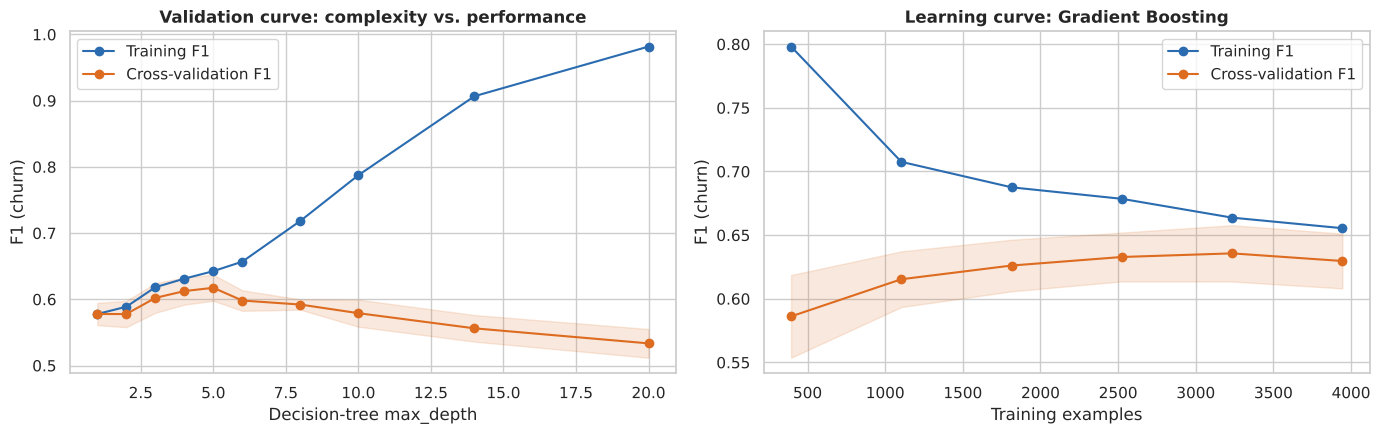

In [28]:
# ---- Over-/under-fitting diagnostics ----
gap = pd.DataFrame({"Train F1 (default)": default_tbl["Train_F1"], "Test F1 (default)": default_tbl["F1"],
                    "Train F1 (tuned)": tuned_tbl["Train_F1"], "Test F1 (tuned)": tuned_tbl["F1"]})
gap["Gap default"] = gap["Train F1 (default)"] - gap["Test F1 (default)"]
gap["Gap tuned"] = gap["Train F1 (tuned)"] - gap["Test F1 (tuned)"]
display(gap.round(4)); RESULTS["gap"] = gap.round(4).to_dict("index")

# Validation curve: decision-tree depth (classic over-fitting illustration)
depths = [1, 2, 3, 4, 5, 6, 8, 10, 14, 20]
vc_pipe = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
tr, va = validation_curve(vc_pipe, X_train, y_train, param_name="clf__max_depth", param_range=depths, cv=CV5, scoring="f1", n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(depths, tr.mean(1), "o-", color="#2B6CB0", label="Training F1"); ax[0].plot(depths, va.mean(1), "o-", color="#DD6B20", label="Cross-validation F1")
ax[0].fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="#DD6B20", alpha=.15)
ax[0].set(xlabel="Decision-tree max_depth", ylabel="F1 (churn)", title="Validation curve: complexity vs. performance"); ax[0].legend()
RESULTS["val_curve"] = {"depths": depths, "train": tr.mean(1).tolist(), "cv": va.mean(1).tolist()}

# Learning curve of the final model
sizes, trs, vas = learning_curve(final_pipe, X_train, y_train, cv=CV5, scoring="f1", train_sizes=np.linspace(.1, 1, 6), n_jobs=-1, random_state=RANDOM_STATE)
ax[1].plot(sizes, trs.mean(1), "o-", color="#2B6CB0", label="Training F1"); ax[1].plot(sizes, vas.mean(1), "o-", color="#DD6B20", label="Cross-validation F1")
ax[1].fill_between(sizes, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), color="#DD6B20", alpha=.15)
ax[1].set(xlabel="Training examples", ylabel="F1 (churn)", title=f"Learning curve: {final_name}"); ax[1].legend()
plt.tight_layout(); save_show(fig, "fig17_val_learning_curve")

**Interpretation**
- **Over-fitting (high variance):** the *default* Decision Tree (train F1 0.996 vs test 0.495, gap 0.50) and Random Forest (0.996 vs 0.542, gap 0.45) memorise the training data. In the validation curve the training F1 of a decision tree climbs to 0.98 as depth grows to 20 while the cross-validation F1 *falls* from its peak of 0.617 (depth 5) to 0.533 - the classic over-fitting picture.
- **After tuning** the train-test gaps shrink to 0.003 (LR), 0.018 (GB), 0.032 (KNN), 0.035 (DT) and 0.089 (RF). Random Forest keeps the largest gap (train F1 0.72), which is typical for bagged deep-ish trees; Gradient Boosting is nicely balanced.
- **Under-fitting (high bias):** a depth-1 tree (a "stump") scores only F1 0.578 on both training and validation data - too simple. Logistic Regression is a simple model with train ~ test performance (gap ~0); it is *not* badly under-fitted since the more flexible models do only slightly better, but it cannot capture interactions.
- **Learning curve (Gradient Boosting):** training and validation F1 converge as the training size grows (0.655 vs 0.629 at full size) and the validation curve is nearly flat after ~2,500 samples - more data of the same kind would bring only small gains; better *features* would help more.

## 13. Interpretation, feature importance and business insights

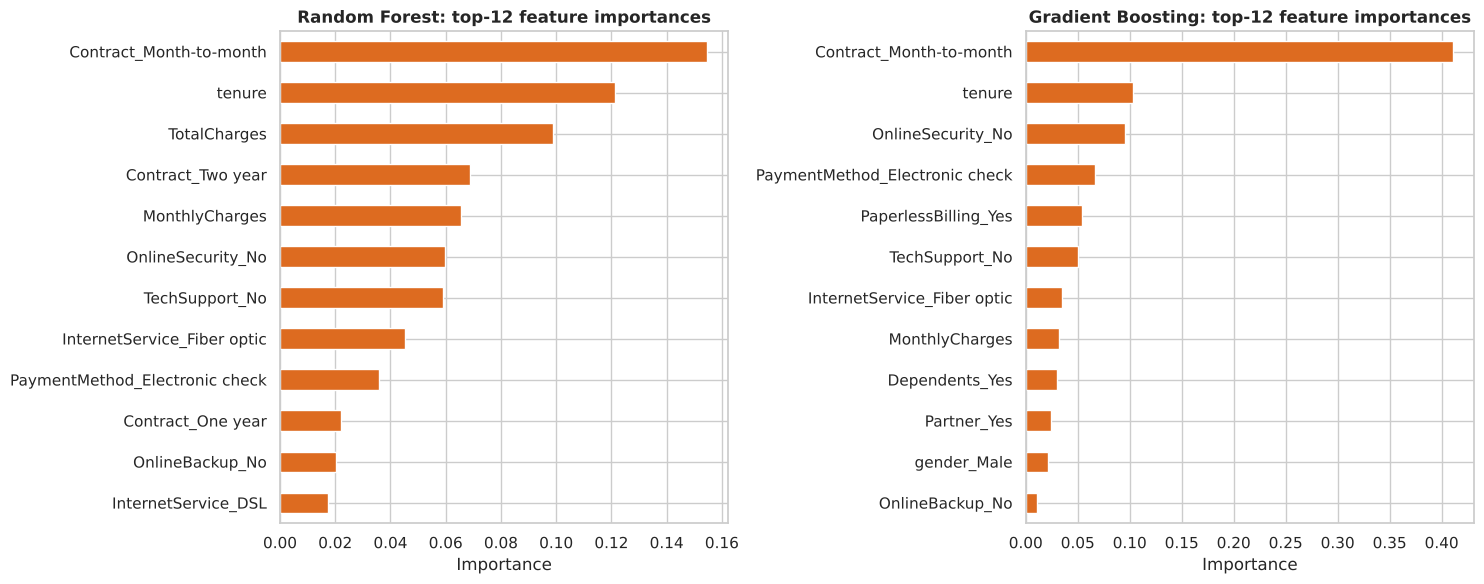

In [29]:
# ---- Feature importance 1: impurity-based importance of the tuned tree ensembles ----
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
imp_store = {}
for a, n in zip(ax, ["Random Forest", "Gradient Boosting"]):
    be = tuned[n].best_estimator_
    names = [x.split("__", 1)[1] for x in be.named_steps["pre"].get_feature_names_out()]
    imp = pd.Series(be.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    imp_store[n] = imp
    imp.head(12)[::-1].plot.barh(color="#DD6B20", ax=a); a.set_title(f"{n}: top-12 feature importances"); a.set_xlabel("Importance")
plt.tight_layout(); save_show(fig, "fig18_importance_trees")
RESULTS["importance_trees"] = {n: s.head(10).to_dict() for n, s in imp_store.items()}

,feature,mean_drop_in_AUC,std
14,Contract,0.0703,0.0071
4,tenure,0.0420,0.0040
7,InternetService,0.0119,0.0028
8,OnlineSecurity,0.0072,0.0025
16,PaymentMethod,0.0055,0.0012
11,TechSupport,0.0052,0.0014
15,PaperlessBilling,0.0037,0.0016
17,MonthlyCharges,0.0021,0.0012
13,StreamingMovies,0.0012,0.0005
18,TotalCharges,0.0009,0.0003


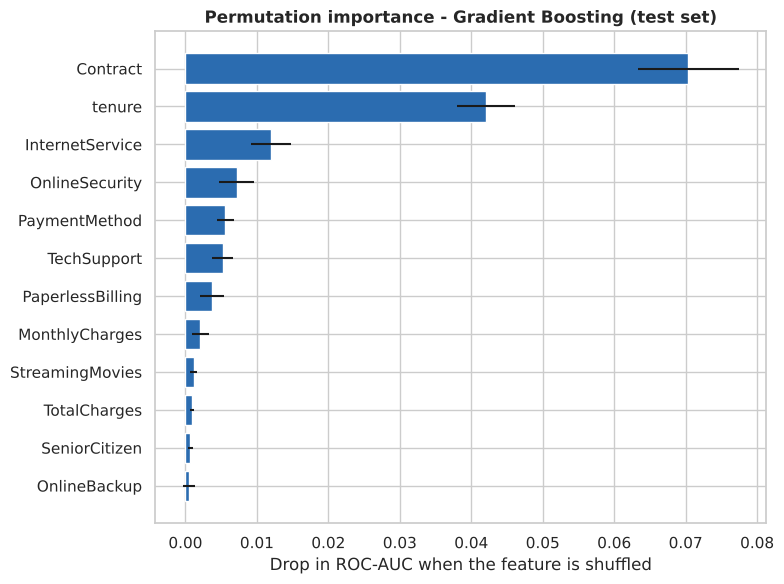

In [30]:
# ---- Feature importance 2: permutation importance of the FINAL model on the TEST set (original, un-encoded columns) ----
pi = permutation_importance(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.DataFrame({"feature": X_test.columns, "mean_drop_in_AUC": pi.importances_mean, "std": pi.importances_std}).sort_values("mean_drop_in_AUC", ascending=False)
display(perm.head(10).round(4))
fig, ax = plt.subplots(figsize=(8, 6))
top = perm.head(12)[::-1]
ax.barh(top["feature"], top["mean_drop_in_AUC"], xerr=top["std"], color="#2B6CB0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled"); ax.set_title(f"Permutation importance - {final_name} (test set)")
plt.tight_layout(); save_show(fig, "fig19_permutation")
RESULTS["permutation_top"] = perm.head(10).set_index("feature")["mean_drop_in_AUC"].to_dict()

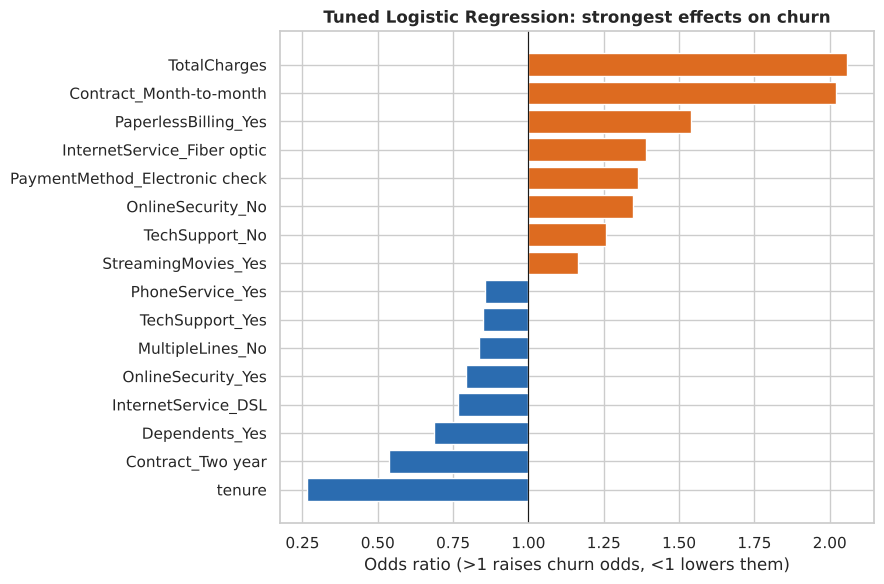

In [31]:
# ---- Feature importance 3: Logistic-Regression odds ratios (direction + size of each effect) ----
lr_best = tuned["Logistic Regression"].best_estimator_
names = [x.split("__", 1)[1] for x in lr_best.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(lr_best.named_steps["clf"].coef_[0], index=names)
odds = np.exp(coef).sort_values()
sel_odds = pd.concat([odds.head(8), odds.tail(8)])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sel_odds.index, sel_odds.values - 1, left=1, color=["#2B6CB0" if v < 1 else "#DD6B20" for v in sel_odds.values])
ax.axvline(1, color="k", lw=.8); ax.set_xlabel("Odds ratio (>1 raises churn odds, <1 lowers them)")
ax.set_title("Tuned Logistic Regression: strongest effects on churn")
plt.tight_layout(); save_show(fig, "fig20_lr_odds")
RESULTS["lr_odds_top"] = {k: float(v) for k, v in sel_odds.items()}

**Interpretation of feature importance (three complementary views)**
1. **Tree-ensemble importance:** in both Random Forest and Gradient Boosting the top feature is **month-to-month contract** (importance 0.15 in RF and 0.41 in GB), followed by **tenure**, then no online security, no tech support, fibre-optic internet and electronic-check payment. In RF, `TotalCharges` and `MonthlyCharges` also rank highly because they can be split many times (a known bias of impurity importance towards continuous variables).
2. **Permutation importance of the final model on the test set** (a more reliable measure - how much AUC drops when one original column is shuffled): **Contract (-0.070 AUC)** and **tenure (-0.042)** are far ahead of `InternetService` (0.012), `OnlineSecurity` (0.007), `PaymentMethod` (0.006) and `TechSupport` (0.005). Demographics such as gender add essentially nothing.
3. **Logistic-regression odds ratios** give the *direction*: a month-to-month contract multiplies the odds of churn by about **2.0**, paperless billing by 1.5, fibre optic by 1.4 and electronic check by 1.4, whereas a two-year contract (0.54), dependents (0.69) and DSL (0.77) reduce them. `tenure` has a strong negative effect (0.27 per standard deviation) and `TotalCharges` an odd positive one (2.06) - the two are 0.83 correlated, so their coefficients partly offset each other (multicollinearity); read them together rather than separately.

**Conclusion:** all methods agree - **contract type and tenure drive churn**, followed by service quality add-ons (security, tech support), internet type and payment method.

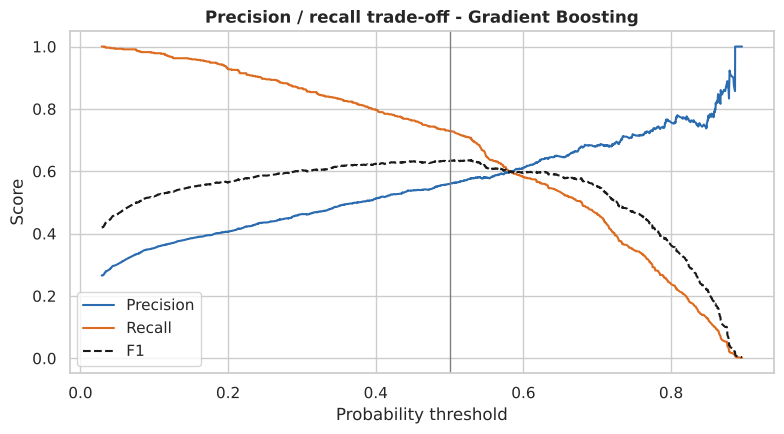

,threshold,flagged_customers,precision,recall,F1
0,0.3,1050,0.4629,0.8663,0.6034
1,0.4,872,0.5126,0.7968,0.6239
2,0.5,731,0.5595,0.7291,0.6331
3,0.6,532,0.6128,0.5811,0.5965


Monthly revenue of customers who actually churned (test set): 41,029
... of which the model flagged correctly: 30,276 (73.8%)


In [32]:
# ---- Business view: choosing the decision threshold of the final model ----
pr, rc, th = precision_recall_curve(y_test, proba_f)
f1s = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(th, pr[:-1], color="#2B6CB0", label="Precision"); ax.plot(th, rc[:-1], color="#DD6B20", label="Recall"); ax.plot(th, f1s, color="k", ls="--", label="F1")
ax.axvline(0.5, color="gray", lw=1); ax.set(xlabel="Probability threshold", ylabel="Score", title=f"Precision / recall trade-off - {final_name}"); ax.legend()
plt.tight_layout(); save_show(fig, "fig21_threshold")

rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p_ = (proba_f >= t).astype(int)
    rows.append({"threshold": t, "flagged_customers": int(p_.sum()), "precision": precision_score(y_test, p_), "recall": recall_score(y_test, p_), "F1": f1_score(y_test, p_)})
thr_tbl = pd.DataFrame(rows); display(thr_tbl.round(4)); RESULTS["threshold_table"] = thr_tbl.round(4).to_dict("records")

# Monthly revenue of actual churners that the model catches (test set)
mc = X_test["MonthlyCharges"].values
caught = mc[(pred_f == 1) & (y_test.values == 1)].sum(); total_churn_rev = mc[y_test.values == 1].sum()
print(f"Monthly revenue of customers who actually churned (test set): {total_churn_rev:,.0f}")
print(f"... of which the model flagged correctly: {caught:,.0f} ({caught/total_churn_rev*100:.1f}%)")
RESULTS["revenue"] = {"churn_monthly_revenue": float(total_churn_rev), "caught": float(caught), "share_caught": float(caught / total_churn_rev)}

**Interpretation.** The default threshold of 0.5 flags 731 of 2,113 customers. Lowering it to 0.3 flags 1,050 customers and catches **86.6 %** of churners but only 46.3 % of the flagged customers really leave; raising it to 0.6 flags 532 customers with 61.3 % precision but only 58.1 % recall. So the threshold is a **business decision**: if a retention offer is cheap compared with the revenue lost, use a lower threshold; if the offer is costly (e.g. big discount), use a higher one. At the default threshold the final model flags correctly customers who pay **30,276 per month in total - 73.8 % of the 41,029 monthly revenue of customers who actually churned** in the test set.

In [33]:
# Business segments: churn rate and monthly revenue by contract / internet service (full data set)
seg = df.groupby(["Contract", "InternetService"]).agg(customers=("Churn_flag", "size"), churn_rate=("Churn_flag", "mean"), avg_monthly=("MonthlyCharges", "mean")).round(3)
seg["churn_rate"] = (seg["churn_rate"] * 100).round(1)
display(seg.sort_values("churn_rate", ascending=False))
RESULTS["segments_top"] = seg.sort_values("churn_rate", ascending=False).head(3).reset_index().to_dict("records")

customers  churn_rate  avg_monthly
Contract       InternetService                                    
Month-to-month Fiber optic           2128        54.6       87.021
               DSL                   1223        32.2       50.220
One year       Fiber optic            539        19.3       98.779
Month-to-month No                     524        18.9       20.410
One year       DSL                    570         9.3       61.397
Two year       Fiber optic            429         7.2      104.571
One year       No                     364         2.5       20.820
Two year       DSL                    628         1.9       70.463
               No                     638         0.8       21.777

### Business insights
1. **Biggest risk segment:** month-to-month customers with fibre-optic internet - **2,128 customers (30 % of the base), churn 54.6 %, average bill 87 per month** - and they are the most valuable per customer. This is the first group to target.
2. **Move customers off month-to-month contracts.** Churn is 42.7 % on month-to-month versus 11.3 % (1 year) and 2.8 % (2 years). Offering a small discount or a free add-on for a 12-month commitment is probably the cheapest churn-reduction tool.
3. **Protect the first year.** 47 % of customers with up to 12 months of tenure churn. An onboarding programme (welcome call, usage tips, first-year check-in) targets exactly this window.
4. **Bundle security and tech support.** Customers without Online Security or Tech Support churn about 2.8x as often as customers with them (41.8 % vs 14.6 %, 41.6 % vs 15.2 %). Free trials of these services can raise satisfaction (association, not proof of causation).
5. **Fix the payment experience.** Electronic-check users churn at 45 %, versus 15-17 % for automatic payment. Encourage a switch to auto-pay (small bill credit).
6. **Investigate fibre-optic quality/pricing** - customers paying the most are the most likely to leave, which may indicate a service or price-value problem.
7. **Using the model:** score every customer monthly, send the top-risk group (threshold chosen from the cost of an offer) to the retention team, and measure the offer's success with a control group.

## 14. Limitations, challenges, future improvements and deployment
**Limitations**
- **Moderate ceiling:** AUC ~0.84 and F1 ~0.63 - roughly one in two flagged customers is a false alarm. The data lack behavioural information (call quality, complaints, usage trends, competitor offers) that drives real churn decisions.
- **Snapshot data:** one row per customer, no time dimension; the model cannot see *when* behaviour changes. No information on the date range, so we cannot validate over time.
- **Associations, not causes:** e.g. "no tech support -> more churn" does not prove that offering tech support will reduce churn.
- **SMOTE** interpolates between one-hot encoded columns and creates "in-between" categories that do not exist in reality; class weights give similar results, so this has little practical impact, but it is a theoretical weakness.
- The train/test split is **one random split**; CV helps, but different splits can shift scores by about +/-0.02 F1. Differences between the top three models are within this noise.
- Single data source (one company / region); results may not transfer to other operators or countries. Fairness: features such as SeniorCitizen should be used with care when making retention decisions.

**Challenges faced**
- Hidden missing values (blank `TotalCharges` stored as text).
- Class imbalance, which made default accuracy misleading and recall low.
- Over-fitting of Decision Tree / Random Forest (train accuracy 0.998 vs test 0.73-0.78).
- Avoiding leakage: encoding, scaling and SMOTE had to be put inside a pipeline so that they are re-fitted in every CV fold.
- Multicollinearity between `tenure` and `TotalCharges`, and the trade-off between accuracy and recall.
- The Kaggle/UCI sites were not reachable from the work environment, so the original IBM copy of the data was used (identical shape and statistics).

**Future improvements**
- Add behavioural / time-series features (monthly usage, complaints, support calls, price changes) and re-train regularly.
- Try XGBoost / LightGBM / CatBoost, stacking, and probability calibration; use cost-sensitive learning with real costs of an offer and of a lost customer.
- Use SHAP values for per-customer explanations; use survival analysis to predict *when* churn happens.
- Use repeated or nested cross-validation and a time-based hold-out set for more reliable comparison.
- Run an A/B test of retention offers to measure real uplift (uplift modelling).

**Possible real-world deployment**
- Save the pipeline (`model/final_model.joblib`) and serve it through a REST API (Flask / FastAPI) or the included Streamlit demo (`app.py`).
- Monthly batch scoring of all customers -> top-risk list pushed to CRM / call-centre tools with the top reasons for each customer.
- Monitor data drift and performance (precision of the retention list), retrain quarterly.

In [34]:
joblib.dump(final_pipe, "model/final_model.joblib")
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)
print("Saved model/final_model.joblib and results.json")
print("Figures:", sorted(os.listdir("figures")))

Saved model/final_model.joblib and results.json
Figures: ['fig01_target.png', 'fig02_numeric_dist.png', 'fig03_boxplots.png', 'fig04_cat_churn.png', 'fig05_corr_heatmap.png', 'fig06_top_corr.png', 'fig07_tenure_contract.png', 'fig08_baseline_cm.png', 'fig09_baseline_compare.png', 'fig10_tree_illustration.png', 'fig11_imbalance.png', 'fig12_before_after.png', 'fig13_cv_box.png', 'fig14_roc_pr.png', 'fig15_final_cm.png', 'fig16_all_tuned_cm.png', 'fig17_val_learning_curve.png', 'fig18_importance_trees.png', 'fig19_permutation.png', 'fig20_lr_odds.png', 'fig21_threshold.png']


## 15. Conclusion
- The **Telco Customer Churn** data (7,043 customers, 26.5 % churn) were cleaned (11 hidden missing values), explored and split 70/30 without data leakage.
- Five models were built: Logistic Regression, Decision Tree, KNN (baseline) and Random Forest, Gradient Boosting (advanced). The best *default* model was Logistic Regression (F1 0.610, AUC 0.845), while default Decision Tree and Random Forest strongly over-fitted.
- **Class-imbalance handling** (class weights / SMOTE) raised recall from about 0.5 to 0.7-0.8; **GridSearchCV** + **5-fold cross-validation** raised F1 of every model and removed most over-fitting.
- The **final model is a tuned Gradient Boosting classifier: accuracy 0.776, precision 0.560, recall 0.729, F1 0.633, ROC-AUC 0.840** on the untouched test set (CV F1 0.634 - consistent). Tuned Logistic Regression and Random Forest perform almost the same, so a simple model is nearly as good.
- **Contract type and tenure are the main drivers of churn**, followed by missing security/tech-support add-ons, fibre-optic internet and electronic-check payment. Month-to-month fibre customers (54.6 % churn) are the priority retention target.
- The model can flag about three quarters of the revenue that would otherwise be lost to churn, but its precision of 56 % means retention offers must be low-cost and the threshold should be set according to business costs.

## Optional deployment demo
`app.py` (included with this submission) is a small **Streamlit** app that loads `model/final_model.joblib` and predicts churn probability from a form. Run with `pip install streamlit` then `streamlit run app.py`.

## References
1. IBM Business Analytics Community - *Telco Customer Churn sample data set* (original source of the data). <https://github.com/IBM/telco-customer-churn-on-icp4d>
2. Kaggle - *Telco Customer Churn* (BlastChar). <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>
3. Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825-2830.
4. Chawla, Bowyer, Hall, Kegelmeyer (2002). *SMOTE: Synthetic Minority Over-sampling Technique.* JAIR 16, 321-357.
5. Lemaitre, Nogueira, Aridas (2017). *Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning.* JMLR 18(17), 1-5.
6. Breiman, L. (2001). *Random Forests.* Machine Learning 45, 5-32.
7. Friedman, J. H. (2001). *Greedy function approximation: a gradient boosting machine.* Annals of Statistics 29(5), 1189-1232.